# Projet qualite de l'eau 2022

Ce notebook contient les etapes utiles du projet :
- `TP1` : nettoyage, selection des parametres et verification du perimetre ;
- `TP2` : agregations annuelles et clustering ;
- `TP3` : visualisation geographique et interpretation.


## 0. Mise en place — dépendances

Exécuter la cellule suivante pour installer les bibliothèques nécessaires.


In [34]:
%pip install pandas pyarrow zstandard matplotlib seaborn scikit-learn geopandas pyogrio shapely


## 0.1 Mise en place Colab — Google Drive

Si `analyse_qualite_eau_2022.zip` est stocké sur Google Drive, monter le Drive avec la cellule suivante. En local, ignorer les cellules de montage et d’extraction.


In [2]:
try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    print("Cellule a utiliser sur Google Colab.")


Mounted at /content/drive


## 0.2 Mise en place Colab — extraction du projet

L’archive `analyse_qualite_eau_2022.zip` contient le notebook, le README et `data/`, directement ou dans un dossier parent. La cellule détecte le dossier contenant les trois tables et le définit comme répertoire de travail. Elle extrait dans `/content/projet_eau_extrait`.


In [ ]:
from pathlib import Path
from zipfile import ZipFile
import os

ARCHIVE_NAME = "analyse_qualite_eau_2022.zip"
ZIP_CANDIDATES = [
    Path("/content") / ARCHIVE_NAME,
    Path("/content/drive/MyDrive") / ARCHIVE_NAME,
    Path("/content/drive/MyDrive/Envir") / ARCHIVE_NAME,
]
EXTRACT_DIR = Path("/content/projet_eau_extrait")
REQUIRED_TABLES = ("stations", "operations_2022", "analyses_2022")


def find_project_root(folder):
    candidates = sorted({
        data.parent for data in folder.rglob("data")
        if data.is_dir() and "__MACOSX" not in data.parts
        and all(
            (data / f"{stem}.csv").is_file()
            or (data / f"{stem}.csv.zst").is_file()
            for stem in REQUIRED_TABLES
        )
    })
    if len(candidates) != 1:
        raise ValueError(
            "L’archive doit contenir un seul dossier data avec stations, "
            "operations_2022 et analyses_2022 au format .csv ou .csv.zst. "
            f"Dossiers valides trouvés : {len(candidates)}."
        )
    return candidates[0]


zip_path = next((p for p in ZIP_CANDIDATES if p.is_file()), None)
if zip_path is None:
    raise FileNotFoundError(
        f"Archive introuvable : {ARCHIVE_NAME}. La placer dans /content, "
        "/content/drive/MyDrive ou /content/drive/MyDrive/Envir."
    )

EXTRACT_DIR.mkdir(parents=True, exist_ok=True)
with ZipFile(zip_path) as archive:
    # Vérifier que tous les fichiers restent dans le dossier d’extraction.
    for member in archive.infolist():
        target = (EXTRACT_DIR / member.filename).resolve()
        if not target.is_relative_to(EXTRACT_DIR.resolve()):
            raise ValueError(f"Chemin invalide dans l’archive : {member.filename}")
    archive.extractall(EXTRACT_DIR)

PROJECT_ROOT = find_project_root(EXTRACT_DIR)
os.chdir(PROJECT_ROOT)
print(f"Projet extrait depuis : {zip_path}")
print(f"Répertoire de travail : {PROJECT_ROOT}")
print(f"Données : {PROJECT_ROOT / 'data'}")


In [4]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 200)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid")


## 1. TP1 - Parametrage

Le fichier `analyses_2022.csv` est volumineux. On lit donc par morceaux et on fixe des choix explicites des le debut.


In [ ]:
PROJECT_ROOT = Path.cwd()
DATA_DIR = PROJECT_ROOT / "data"
CACHE_DIR = PROJECT_ROOT / "cache"
CACHE_DIR.mkdir(exist_ok=True)

def resolve_table_path(stem: str) -> Path:
    csv_path = DATA_DIR / f"{stem}.csv"
    zst_path = DATA_DIR / f"{stem}.csv.zst"

    if csv_path.exists():
        return csv_path
    if zst_path.exists():
        return zst_path
    raise FileNotFoundError(f"Fichier introuvable pour {stem}: ni CSV ni CSV.ZST")


STATIONS_PATH = resolve_table_path("stations")
OPERATIONS_PATH = resolve_table_path("operations_2022")
ANALYSES_PATH = resolve_table_path("analyses_2022")

CHUNK_SIZE = 300_000
KEEP_QUALITIES = {"Correcte"}  # Ajouter "Incertaine" plus tard pour un test de sensibilite.

CORE_PARAMS = {
    "1295": "Turbidite Formazine Nephelometrique",
    "1301": "Temperature de l'Eau",
    "1302": "Potentiel en Hydrogene (pH)",
    "1303": "Conductivite a 25C",
    "1305": "Matieres en suspension",
    "1311": "Oxygene dissous",
    "1312": "Taux de saturation en oxygene",
    "1313": "DBO5",
    "1314": "DCO",
    "1319": "Azote Kjeldahl",
    "1335": "Ammonium",
    "1339": "Nitrites",
    "1340": "Nitrates",
    "1350": "Phosphore total",
    "1433": "Orthophosphates (PO4)",
    "1841": "Carbone Organique",
}

PREFERRED_FRACTIONS = {
    "1295": {"Eau brute"},
    "1301": {"Eau brute"},
    "1302": {"Eau brute"},
    "1303": {"Eau brute"},
    "1305": {"Eau brute"},
    "1311": {"Eau brute"},
    "1312": {"Eau brute"},
    "1313": {"Eau brute"},
    "1314": {"Eau brute"},
    "1319": {"Eau brute"},
    "1335": {"Phase aqueuse de l'eau (filtrée, centrifugée...)"},
    "1339": {"Phase aqueuse de l'eau (filtrée, centrifugée...)"},
    "1340": {"Phase aqueuse de l'eau (filtrée, centrifugée...)"},
    "1350": {"Eau brute"},
    "1433": {"Phase aqueuse de l'eau (filtrée, centrifugée...)"},
    "1841": {"Phase aqueuse de l'eau (filtrée, centrifugée...)"},
}

STATION_COLUMNS = [
    "CdStationMesureEauxSurface",
    "LbStationMesureEauxSurface",
    "CoordXStationMesureEauxSurface",
    "CoordYStationMesureEauxSurface",
    "CodeDepartement",
    "LbDepartement",
    "CodeRegion",
    "LbRegion",
    "NomMasseDEau",
    "NomSsBassinDCEAdmin",
    "NomEuBassinDCE",
    "NomCoursdEau",
    "LibelleTypEthStationMesureEauxSurface",
    "LibelleNatureStationMesureEauxSurface",
    "AltitudePointCaracteritisque",
    "SuperficieBassinVersantReel",
    "SuperficieBassinVersantTopo",
]

OPERATION_COLUMNS = [
    "CdStationMesureEauxSurface",
    "CdPrelevement",
    "CoordXPrel",
    "CoordYPrel",
    "CdSupport",
    "LbSupport",
    "DatePrel",
    "HeurePrel",
    "NomRdd",
]

ANALYSIS_COLUMNS = [
    "CdStationMesureEauxSurface",
    "CdPrelevement",
    "DatePrel",
    "CdSupport",
    "LbSupport",
    "CdFractionAnalysee",
    "LbFractionAnalysee",
    "CdParametre",
    "LbLongParamètre",
    "RsAna",
    "SymUniteMesure",
    "CdRqAna",
    "MnemoRqAna",
    "LdAna",
    "LqAna",
    "LsAna",
    "CdQualAna",
    "LbQualAna",
    "CommentairesAna",
    "ComResultatAna",
]

NUMERIC_ANALYSIS_COLUMNS = ["RsAna", "LdAna", "LqAna", "LsAna"]


## 2. TP1 - Chargement des stations


In [6]:
stations = pd.read_csv(
    STATIONS_PATH,
    sep=";",
    usecols=STATION_COLUMNS,
    dtype="string",
    low_memory=False,
    compression="infer",
)

stations_scope = stations.loc[
    stations["LibelleTypEthStationMesureEauxSurface"].eq("Station qualité située sur un cours d'eau")
].copy()

for col in [
    "CoordXStationMesureEauxSurface",
    "CoordYStationMesureEauxSurface",
    "AltitudePointCaracteritisque",
    "SuperficieBassinVersantReel",
    "SuperficieBassinVersantTopo",
]:
    stations_scope[col] = pd.to_numeric(stations_scope[col], errors="coerce")

print(f"Stations lues : {len(stations):,}")
print(f"Stations retenues (cours d'eau) : {len(stations_scope):,}")

stations_scope.head()


Stations lues : 22,110
Stations retenues (cours d'eau) : 21,530


,CdStationMesureEauxSurface,LbStationMesureEauxSurface,CoordXStationMesureEauxSurface,CoordYStationMesureEauxSurface,CodeDepartement,LbDepartement,CodeRegion,LbRegion,NomMasseDEau,NomSsBassinDCEAdmin,NomEuBassinDCE,NomCoursdEau,LibelleTypEthStationMesureEauxSurface,LibelleNatureStationMesureEauxSurface,AltitudePointCaracteritisque,SuperficieBassinVersantReel,SuperficieBassinVersantTopo
2,01083000,LE CANAL DE LENS À HARNES (62),694108.84,7038840.78,62,Pas-de-Calais,32,Hauts-de-France,<NA>,<NA>,<NA>,<NA>,Station qualité située sur un cours d'eau,Station de mesure Manuelle,29.47,<NA>,<NA>
3,02054100,LA MOSELLE À CHAVELOT,955373.0,6798229.0,88,Vosges,44,Grand Est,<NA>,<NA>,<NA>,<NA>,Station qualité située sur un cours d'eau,Nature de la station inconnue,310.0,<NA>,1257.14
4,02057503,LE REVAU À VAUDEVILLE,935577.0,6822741.0,54,Meurthe-et-Moselle,44,Grand Est,<NA>,<NA>,<NA>,<NA>,Station qualité située sur un cours d'eau,Nature de la station inconnue,244.0,<NA>,<NA>
5,02082350,LA SEILLE À CHEMINOT,928813.0,6875754.0,57,Moselle,44,Grand Est,<NA>,<NA>,<NA>,<NA>,Station qualité située sur un cours d'eau,Nature de la station inconnue,180.0,<NA>,1042.93
6,02116650,LA GIVONNE À LA-MONCELLE,843519.0,6956186.0,08,Ardennes,44,Grand Est,<NA>,<NA>,<NA>,<NA>,Station qualité située sur un cours d'eau,Nature de la station inconnue,170.0,<NA>,44.2


## 3. TP1 - Chargement des prelevements 2022

On garde seulement les prelevements sur le support `Eau`, puis on restreint aux stations de cours d'eau.


In [7]:
operations = pd.read_csv(
    OPERATIONS_PATH,
    sep=";",
    usecols=OPERATION_COLUMNS,
    dtype="string",
    low_memory=False,
    compression="infer",
)

operations["DatePrel"] = pd.to_datetime(operations["DatePrel"], errors="coerce")

for col in ["CoordXPrel", "CoordYPrel"]:
    operations[col] = pd.to_numeric(operations[col], errors="coerce")

operations_eau = operations.loc[operations["LbSupport"].eq("Eau")].copy()
operations_eau = operations_eau.merge(
    stations_scope[["CdStationMesureEauxSurface"]],
    on="CdStationMesureEauxSurface",
    how="inner",
    validate="m:1",
)

duplicate_operation_keys = operations_eau.duplicated(
    ["CdStationMesureEauxSurface", "CdPrelevement"],
    keep=False,
).sum()
print(
    "Doublons cote operations sur la clef station/prelevement : "
    f"{duplicate_operation_keys:,} lignes"
)
print("La jointure finale utilisera station + prelevement + date pour lever cette ambiguite.")

print(f"Prelevements lus : {len(operations):,}")
print(f"Prelevements retenus (support Eau + cours d'eau) : {len(operations_eau):,}")
print(f"Stations couvertes : {operations_eau['CdStationMesureEauxSurface'].nunique():,}")

operations_eau.head()


Doublons cote operations sur la clef station/prelevement : 14 lignes
La jointure finale utilisera station + prelevement + date pour lever cette ambiguite.
Prelevements lus : 27,740
Prelevements retenus (support Eau + cours d'eau) : 23,072
Stations couvertes : 3,502


,CdStationMesureEauxSurface,CdPrelevement,CoordXPrel,CoordYPrel,CdSupport,LbSupport,DatePrel,HeurePrel,NomRdd
0,01000455,01000455202208170937222223,616857.52,7053666.78,3,Eau,2022-08-17,09:37:00,Réseau de suivi local de l’opération de restau...
1,01000457,01000457202208171054222223,613745.31,7048324.23,3,Eau,2022-08-17,10:54:00,Réseau de suivi local de l’opération de restau...
2,01002236,01002236202208171120222223,614157.15,7046277.46,3,Eau,2022-08-17,11:20:00,Réseau de suivi local de l’opération de restau...
3,01002237,01002237202201241010222223,633578.791,7079859.79,3,Eau,2022-01-24,10:10:00,Réseau de suivi local de l’opération de restau...
4,01002237,01002237202202211129222223,633578.791,7079859.79,3,Eau,2022-02-21,11:29:00,Réseau de suivi local de l’opération de restau...


## 4. TP1 - Chargement filtre des analyses 2022

Lecture par morceaux pour eviter de charger tout le CSV en memoire. On filtre simultanement :
- support `Eau` ;
- parametres du noyau physico-chimique ;
- qualites retenues ;
- fraction analysee coherente par parametre ;
- `RsAna`, c'est-a-dire la valeur numerique du resultat d'analyse.


In [8]:
def load_filtered_analyses(path: Path, chunk_size: int = CHUNK_SIZE) -> pd.DataFrame:
    dtype_map = {col: "string" for col in ANALYSIS_COLUMNS}
    frames = []
    rows_read = 0
    rows_kept = 0
    rows_missing_rsana = 0

    reader = pd.read_csv(
        path,
        sep=";",
        usecols=ANALYSIS_COLUMNS,
        dtype=dtype_map,
        chunksize=chunk_size,
        low_memory=False,
        compression="infer",
    )

    for chunk_id, chunk in enumerate(reader, start=1):
        rows_read += len(chunk)

        mask = (
            chunk["LbSupport"].eq("Eau")
            & chunk["CdParametre"].isin(CORE_PARAMS)
            & chunk["LbQualAna"].isin(KEEP_QUALITIES)
        )
        chunk = chunk.loc[mask].copy()

        if chunk.empty:
            print(f"chunk {chunk_id:02d}: 0 ligne gardee")
            continue

        fraction_mask = pd.Series(False, index=chunk.index)
        for param_code, allowed_fractions in PREFERRED_FRACTIONS.items():
            fraction_mask |= (
                chunk["CdParametre"].eq(param_code)
                & chunk["LbFractionAnalysee"].isin(allowed_fractions)
            )
        chunk = chunk.loc[fraction_mask].copy()

        if chunk.empty:
            print(f"chunk {chunk_id:02d}: 0 ligne gardee apres filtre fraction")
            continue

        chunk["DatePrel"] = pd.to_datetime(chunk["DatePrel"], errors="coerce")
        for col in NUMERIC_ANALYSIS_COLUMNS:
            chunk[col] = pd.to_numeric(chunk[col].str.replace(",", ".", regex=False), errors="coerce")

        rows_before_rsana = len(chunk)
        chunk = chunk.loc[chunk["RsAna"].notna()].copy()
        rows_missing_rsana += rows_before_rsana - len(chunk)

        if chunk.empty:
            print(f"chunk {chunk_id:02d}: 0 ligne gardee apres filtre RsAna")
            continue

        rows_kept += len(chunk)
        frames.append(chunk)
        print(f"chunk {chunk_id:02d}: {len(chunk):,} lignes gardees ({rows_kept:,} cumulees)")

    if not frames:
        raise ValueError("Aucune analyse retenue. Verifier les filtres.")

    result = pd.concat(frames, ignore_index=True)
    print(f"Lignes lues : {rows_read:,}")
    print(f"Lignes retenues avec RsAna renseigne : {len(result):,}")
    print(f"Lignes ecartees car RsAna manquant : {rows_missing_rsana:,}")
    return result


In [9]:
analyses = load_filtered_analyses(ANALYSES_PATH)

duplicate_key = ["CdStationMesureEauxSurface", "CdPrelevement", "CdParametre"]
n_duplicates = analyses.duplicated(duplicate_key, keep=False).sum()
print(f"Doublons potentiels sur la clef station/prelevement/parametre : {n_duplicates:,}")

analyses = (
    analyses.sort_values(duplicate_key + ["DatePrel"])
    .drop_duplicates(duplicate_key, keep="first")
    .reset_index(drop=True)
)

print(f"Analyses apres dedoublonnage simple : {len(analyses):,}")
analyses.head()


chunk 01: 16,185 lignes gardees (16,185 cumulees)
chunk 02: 9,824 lignes gardees (26,009 cumulees)
chunk 03: 14,832 lignes gardees (40,841 cumulees)
chunk 04: 9,338 lignes gardees (50,179 cumulees)
chunk 05: 10,315 lignes gardees (60,494 cumulees)
chunk 06: 25,305 lignes gardees (85,799 cumulees)
chunk 07: 14,218 lignes gardees (100,017 cumulees)
chunk 08: 9,283 lignes gardees (109,300 cumulees)
chunk 09: 9,399 lignes gardees (118,699 cumulees)
chunk 10: 9,032 lignes gardees (127,731 cumulees)
chunk 11: 10,688 lignes gardees (138,419 cumulees)
chunk 12: 8,609 lignes gardees (147,028 cumulees)
chunk 13: 8,901 lignes gardees (155,929 cumulees)
chunk 14: 9,067 lignes gardees (164,996 cumulees)
chunk 15: 8,710 lignes gardees (173,706 cumulees)
chunk 16: 9,019 lignes gardees (182,725 cumulees)
chunk 17: 9,246 lignes gardees (191,971 cumulees)
chunk 18: 9,934 lignes gardees (201,905 cumulees)
chunk 19: 10,805 lignes gardees (212,710 cumulees)
chunk 20: 9,375 lignes gardees (222,085 cumulees)

/tmp/ipykernel_16635/2261023078.py:63: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  result = pd.concat(frames, ignore_index=True)


Lignes lues : 8,794,608
Lignes retenues avec RsAna renseigne : 354,751
Lignes ecartees car RsAna manquant : 1,938
Doublons potentiels sur la clef station/prelevement/parametre : 1,220
Analyses apres dedoublonnage simple : 354,141


,CdStationMesureEauxSurface,CdSupport,LbSupport,CdFractionAnalysee,LbFractionAnalysee,CdPrelevement,DatePrel,CdParametre,LbLongParamètre,RsAna,SymUniteMesure,CdRqAna,MnemoRqAna,LdAna,LqAna,LsAna,CdQualAna,LbQualAna,CommentairesAna,ComResultatAna
0,01000455,3,Eau,23,Eau brute,01000455202208170937222223,2022-08-17,1295,Turbidité Formazine Néphélométrique,4.32,NFU,1,Résultat > seuil de quantification et < au seu...,0.03,0.1,<NA>,1,Correcte,<NA>,<NA>
1,01000455,3,Eau,23,Eau brute,01000455202208170937222223,2022-08-17,1301,Température de l'Eau,13.2,°C,1,Résultat > seuil de quantification et < au seu...,<NA>,<NA>,<NA>,1,Correcte,<NA>,<NA>
2,01000455,3,Eau,23,Eau brute,01000455202208170937222223,2022-08-17,1302,Potentiel en Hydrogène (pH),7.9,unité pH,1,Résultat > seuil de quantification et < au seu...,<NA>,<NA>,<NA>,1,Correcte,<NA>,<NA>
3,01000455,3,Eau,23,Eau brute,01000455202208170937222223,2022-08-17,1303,Conductivité à 25°C,584.0,µS/cm,1,Résultat > seuil de quantification et < au seu...,10.0,30.0,<NA>,1,Correcte,<NA>,<NA>
4,01000455,3,Eau,23,Eau brute,01000455202208170937222223,2022-08-17,1305,Matières en suspension,3.5,mg/L,1,Résultat > seuil de quantification et < au seu...,0.7,2.0,<NA>,1,Correcte,<NA>,<NA>


## 5. TP1 - Mise en coherence entre stations, prelevements et analyses


In [10]:
operations_for_merge = operations_eau.rename(columns={
    "HeurePrel": "HeurePrelOperation",
    "NomRdd": "NomRddOperation",
})

analysis_base = analyses.merge(
    operations_for_merge,
    on=["CdStationMesureEauxSurface", "CdPrelevement", "DatePrel"],
    how="inner",
    validate="m:1",
)

analysis_base = analysis_base.merge(
    stations_scope,
    on="CdStationMesureEauxSurface",
    how="inner",
    validate="m:1",
)

print(f"Base finale : {len(analysis_base):,} lignes")
print(f"Stations finales : {analysis_base['CdStationMesureEauxSurface'].nunique():,}")
print(f"Prelevements finaux : {analysis_base['CdPrelevement'].nunique():,}")

analysis_base.head()


Base finale : 333,553 lignes
Stations finales : 3,425
Prelevements finaux : 22,256


,CdStationMesureEauxSurface,CdSupport_x,LbSupport_x,CdFractionAnalysee,LbFractionAnalysee,CdPrelevement,DatePrel,CdParametre,LbLongParamètre,RsAna,SymUniteMesure,CdRqAna,MnemoRqAna,LdAna,LqAna,LsAna,CdQualAna,LbQualAna,CommentairesAna,ComResultatAna,CoordXPrel,CoordYPrel,CdSupport_y,LbSupport_y,HeurePrelOperation,NomRddOperation,LbStationMesureEauxSurface,CoordXStationMesureEauxSurface,CoordYStationMesureEauxSurface,CodeDepartement,LbDepartement,CodeRegion,LbRegion,NomMasseDEau,NomSsBassinDCEAdmin,NomEuBassinDCE,NomCoursdEau,LibelleTypEthStationMesureEauxSurface,LibelleNatureStationMesureEauxSurface,AltitudePointCaracteritisque,SuperficieBassinVersantReel,SuperficieBassinVersantTopo
0,01000455,3,Eau,23,Eau brute,01000455202208170937222223,2022-08-17,1295,Turbidité Formazine Néphélométrique,4.32,NFU,1,Résultat > seuil de quantification et < au seu...,0.03,0.1,<NA>,1,Correcte,<NA>,<NA>,616857.52,7053666.78,3,Eau,09:37:00,Réseau de suivi local de l’opération de restau...,LA COURSE/CANCHE À BEUSSENT (62),616857.52,7053666.78,62,Pas-de-Calais,32,Hauts-de-France,<NA>,<NA>,<NA>,<NA>,Station qualité située sur un cours d'eau,Station de mesure Manuelle,0.0,<NA>,0.0
1,01000455,3,Eau,23,Eau brute,01000455202208170937222223,2022-08-17,1301,Température de l'Eau,13.2,°C,1,Résultat > seuil de quantification et < au seu...,<NA>,<NA>,<NA>,1,Correcte,<NA>,<NA>,616857.52,7053666.78,3,Eau,09:37:00,Réseau de suivi local de l’opération de restau...,LA COURSE/CANCHE À BEUSSENT (62),616857.52,7053666.78,62,Pas-de-Calais,32,Hauts-de-France,<NA>,<NA>,<NA>,<NA>,Station qualité située sur un cours d'eau,Station de mesure Manuelle,0.0,<NA>,0.0
2,01000455,3,Eau,23,Eau brute,01000455202208170937222223,2022-08-17,1302,Potentiel en Hydrogène (pH),7.9,unité pH,1,Résultat > seuil de quantification et < au seu...,<NA>,<NA>,<NA>,1,Correcte,<NA>,<NA>,616857.52,7053666.78,3,Eau,09:37:00,Réseau de suivi local de l’opération de restau...,LA COURSE/CANCHE À BEUSSENT (62),616857.52,7053666.78,62,Pas-de-Calais,32,Hauts-de-France,<NA>,<NA>,<NA>,<NA>,Station qualité située sur un cours d'eau,Station de mesure Manuelle,0.0,<NA>,0.0
3,01000455,3,Eau,23,Eau brute,01000455202208170937222223,2022-08-17,1303,Conductivité à 25°C,584.0,µS/cm,1,Résultat > seuil de quantification et < au seu...,10.0,30.0,<NA>,1,Correcte,<NA>,<NA>,616857.52,7053666.78,3,Eau,09:37:00,Réseau de suivi local de l’opération de restau...,LA COURSE/CANCHE À BEUSSENT (62),616857.52,7053666.78,62,Pas-de-Calais,32,Hauts-de-France,<NA>,<NA>,<NA>,<NA>,Station qualité située sur un cours d'eau,Station de mesure Manuelle,0.0,<NA>,0.0
4,01000455,3,Eau,23,Eau brute,01000455202208170937222223,2022-08-17,1305,Matières en suspension,3.5,mg/L,1,Résultat > seuil de quantification et < au seu...,0.7,2.0,<NA>,1,Correcte,<NA>,<NA>,616857.52,7053666.78,3,Eau,09:37:00,Réseau de suivi local de l’opération de restau...,LA COURSE/CANCHE À BEUSSENT (62),616857.52,7053666.78,62,Pas-de-Calais,32,Hauts-de-France,<NA>,<NA>,<NA>,<NA>,Station qualité située sur un cours d'eau,Station de mesure Manuelle,0.0,<NA>,0.0


## 6. TP1 - Verification rapide du perimetre retenu

On poursuit ici le `TP1` avec :
- la completion station x parametre ;
- l'exclusion explicite des lignes sans `RsAna` ;
- une regle simple de filtrage des stations trop incompletes ;
- des statistiques descriptives ;
- des visualisations de distributions ;
- une premiere lecture des correlations entre parametres.


In [11]:
analysis_stats = analysis_base.loc[analysis_base["RsAna"].notna()].copy()
print(
    f"Lignes sans RsAna dans analysis_base : {analysis_base['RsAna'].isna().sum():,}"
)
print(f"Lignes conservees pour les stats TP1 : {len(analysis_stats):,}")

param_summary = (
    analysis_stats.groupby(["CdParametre", "LbLongParamètre"], dropna=False)
    .agg(
        n_analyses=("RsAna", "count"),
        n_stations=("CdStationMesureEauxSurface", "nunique"),
        unite=("SymUniteMesure", lambda s: s.mode().iat[0] if not s.mode().empty else pd.NA),
        fraction=("LbFractionAnalysee", lambda s: s.mode().iat[0] if not s.mode().empty else pd.NA),
    )
    .sort_values("n_analyses", ascending=False)
)

param_summary["share_stations"] = (
    param_summary["n_stations"] / analysis_stats["CdStationMesureEauxSurface"].nunique()
)

param_summary


Lignes sans RsAna dans analysis_base : 0
Lignes conservees pour les stats TP1 : 333,553


,,n_analyses,n_stations,unite,fraction,share_stations
CdParametre,LbLongParamètre,,,,,
1302,Potentiel en Hydrogène (pH),21986,3401,unité pH,Eau brute,0.992993
1303,Conductivité à 25°C,21903,3376,µS/cm,Eau brute,0.985693
1301,Température de l'Eau,21709,3414,°C,Eau brute,0.996788
1311,Oxygène dissous,21621,3394,mg(O2)/L,Eau brute,0.990949
1319,Azote Kjeldahl,21236,3331,mg(N)/L,Eau brute,0.972555
1312,Taux de saturation en oxygène,21227,3344,%,Eau brute,0.976350
1305,Matières en suspension,21208,3330,mg/L,Eau brute,0.972263
1350,Phosphore total,20909,3325,mg(P)/L,Eau brute,0.970803
1295,Turbidité Formazine Néphélométrique,20867,3268,NFU,Eau brute,0.954161


In [12]:
station_param_counts = pd.pivot_table(
    analysis_stats,
    index="CdStationMesureEauxSurface",
    columns="CdParametre",
    values="RsAna",
    aggfunc="count",
    fill_value=0,
)

station_param_presence = station_param_counts.gt(0).astype("int8")

coverage_by_param = (
    station_param_presence.sum(axis=0)
    .rename("n_stations")
    .sort_values(ascending=False)
    .to_frame()
)
coverage_by_param["share_stations"] = (
    coverage_by_param["n_stations"] / station_param_presence.shape[0]
)
coverage_by_param["param_name"] = coverage_by_param.index.map(
    lambda code: CORE_PARAMS.get(str(code), str(code))
)

station_coverage = (
    station_param_presence.sum(axis=1)
    .rename("n_params_present")
    .sort_values(ascending=False)
    .to_frame()
)

display(coverage_by_param)
display(station_coverage.describe())
station_coverage.head()


,n_stations,share_stations,param_name
CdParametre,,,
1301,3414,0.996788,Temperature de l'Eau
1302,3401,0.992993,Potentiel en Hydrogene (pH)
1311,3394,0.990949,Oxygene dissous
1303,3376,0.985693,Conductivite a 25C
1312,3344,0.976350,Taux de saturation en oxygene
1340,3333,0.973139,Nitrates
1319,3331,0.972555,Azote Kjeldahl
1305,3330,0.972263,Matieres en suspension
1350,3325,0.970803,Phosphore total


,n_params_present
count,3425.000000
mean,15.197080
std,1.920284
min,1.000000
25%,15.000000
50%,16.000000
75%,16.000000
max,16.000000


,n_params_present
CdStationMesureEauxSurface,
06830199,16
06830152,16
06830133,16
06830129,16
06830123,16


Seuil de couverture retenu : 10 parametres
Stations retenues : 3,321
Analyses retenues : 331,122


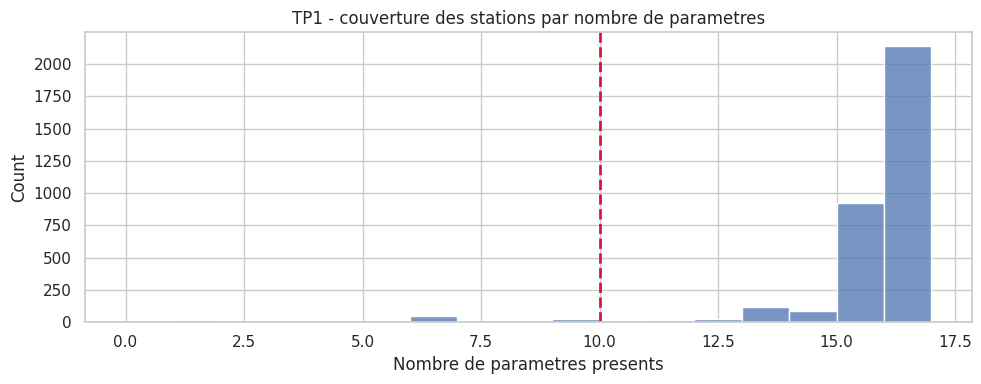

In [13]:
MIN_PARAMS = 10  # Regle initiale a discuter dans le rapport.

eligible_stations = station_coverage.index[
    station_coverage["n_params_present"] >= MIN_PARAMS
]

analysis_tp1 = analysis_stats.loc[
    analysis_stats["CdStationMesureEauxSurface"].isin(eligible_stations)
].copy()
analysis_tp1["ParamLabel"] = analysis_tp1["CdParametre"].map(
    lambda code: f"{code} - {CORE_PARAMS.get(code, code)}"
)

print(f"Seuil de couverture retenu : {MIN_PARAMS} parametres")
print(f"Stations retenues : {analysis_tp1['CdStationMesureEauxSurface'].nunique():,}")
print(f"Analyses retenues : {len(analysis_tp1):,}")

fig, ax = plt.subplots(figsize=(10, 4))
bins = range(0, int(station_coverage["n_params_present"].max()) + 2)
sns.histplot(station_coverage["n_params_present"], bins=bins, ax=ax)
ax.axvline(MIN_PARAMS, color="crimson", linestyle="--", linewidth=2)
ax.set_title("TP1 - couverture des stations par nombre de parametres")
ax.set_xlabel("Nombre de parametres presents")
plt.tight_layout()
plt.show()


### 6.1 TP1 - Statistiques descriptives et distributions


In [14]:
distribution_summary = (
    analysis_tp1.groupby(["CdParametre", "ParamLabel"])["RsAna"]
    .describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95])
    .sort_index()
)

distribution_summary


,,count,mean,std,min,5%,25%,50%,75%,95%,max
CdParametre,ParamLabel,,,,,,,,,,
1295,1295 - Turbidite Formazine Nephelometrique,20742.0,15.811441,130.539776,0.1,1.1,3.0,6.3,13.0,40.0,12000.0
1301,1301 - Temperature de l'Eau,21346.0,12.326821,5.168493,0.0,4.7,8.5,11.7,15.7,21.8,31.5
1302,1302 - Potentiel en Hydrogene (pH),21687.0,7.943871,0.380465,4.0,7.2,7.8,8.0,8.2,8.4,13.3
1303,1303 - Conductivite a 25C,21603.0,539.874759,1038.207217,10.0,116.0,327.0,513.0,632.0,891.0,53500.0
1305,1305 - Matieres en suspension,21168.0,17.803893,110.307427,1.0,1.0,3.5,7.6,15.0,50.0,10400.0
1311,1311 - Oxygene dissous,21353.0,10.143764,2.037058,0.02,6.7,9.0,10.4,11.4,12.8,95.7
1312,1312 - Taux de saturation en oxygene,20950.0,95.214948,14.557411,0.2,70.0,90.025,97.4,101.5,112.1,751.0
1313,1313 - DBO5,20571.0,1.405479,1.21776,0.5,0.5,0.8,1.2,1.7,3.0,92.6
1314,1314 - DCO,17396.0,17.018349,18.099051,5.0,5.0,9.7,20.0,20.0,28.0,1640.0


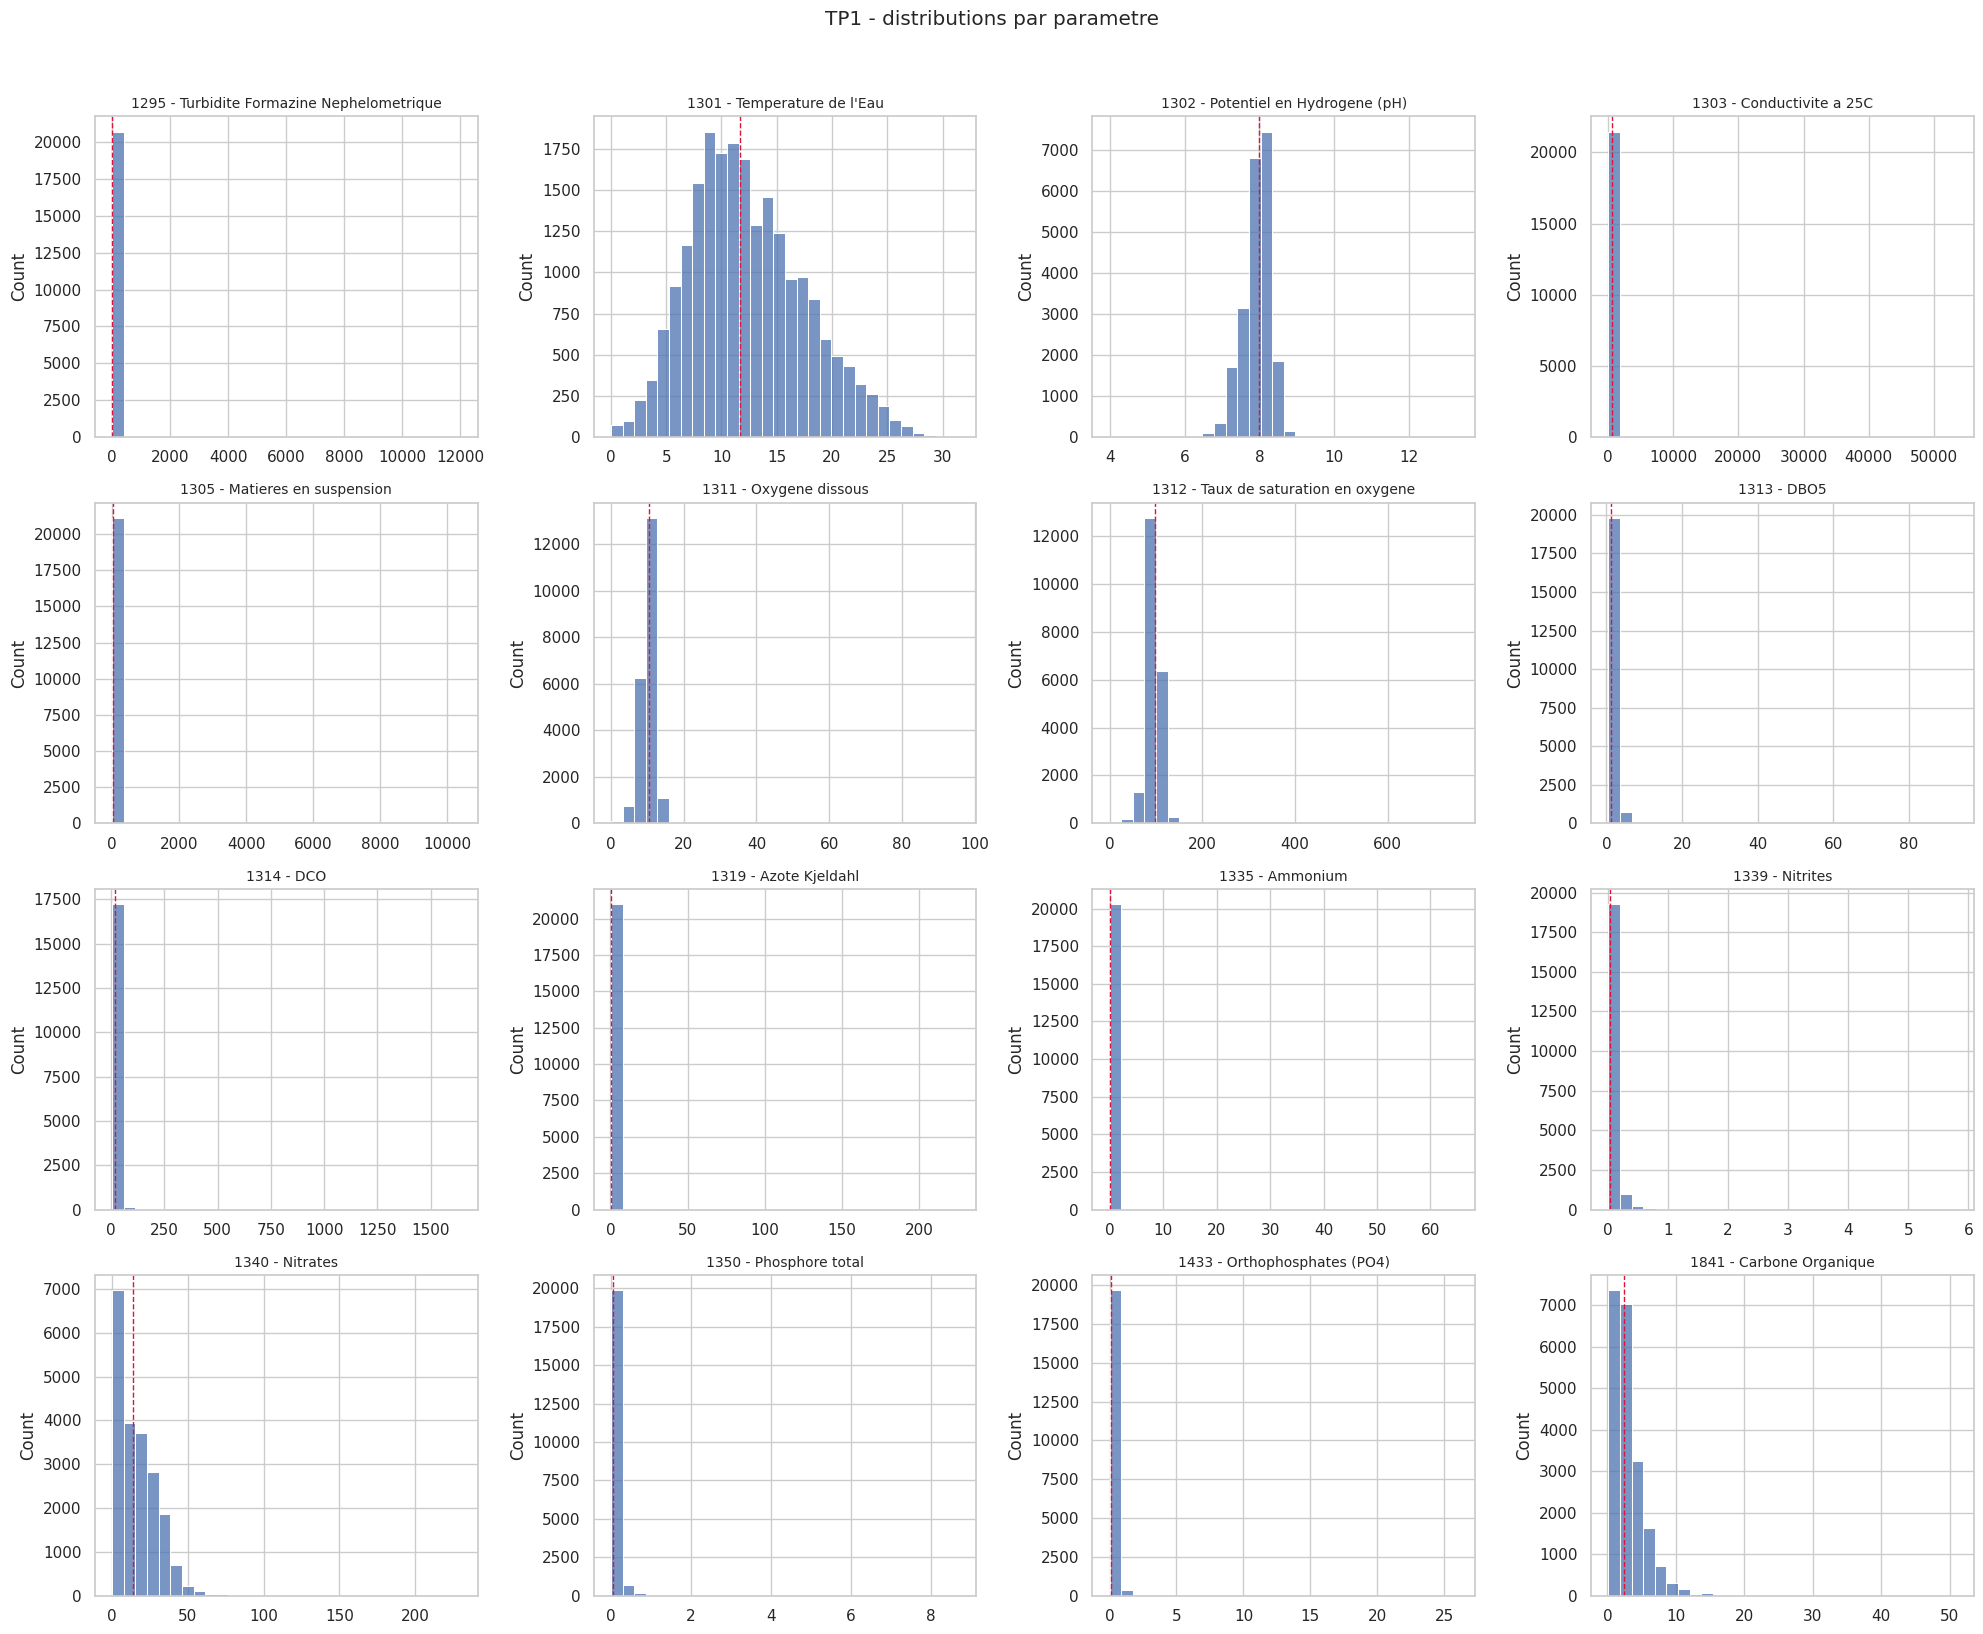

In [15]:
plot_params = list(CORE_PARAMS)
plot_df = analysis_tp1.loc[analysis_tp1["CdParametre"].isin(plot_params)].copy()

fig, axes = plt.subplots(4, 4, figsize=(20, 16))
for ax, code in zip(axes.flat, plot_params):
    label = f"{code} - {CORE_PARAMS[code]}"
    subset = plot_df.loc[plot_df["CdParametre"].eq(code), "RsAna"].dropna()
    if subset.empty:
        ax.set_visible(False)
        continue
    sns.histplot(subset, bins=30, ax=ax)
    ax.axvline(subset.median(), color="crimson", linestyle="--", linewidth=1)
    ax.set_title(label, fontsize=10)
    ax.set_xlabel("")

for ax in axes.flat[len(plot_params):]:
    ax.set_visible(False)

plt.suptitle("TP1 - distributions par parametre", y=1.02)
plt.tight_layout()
plt.show()


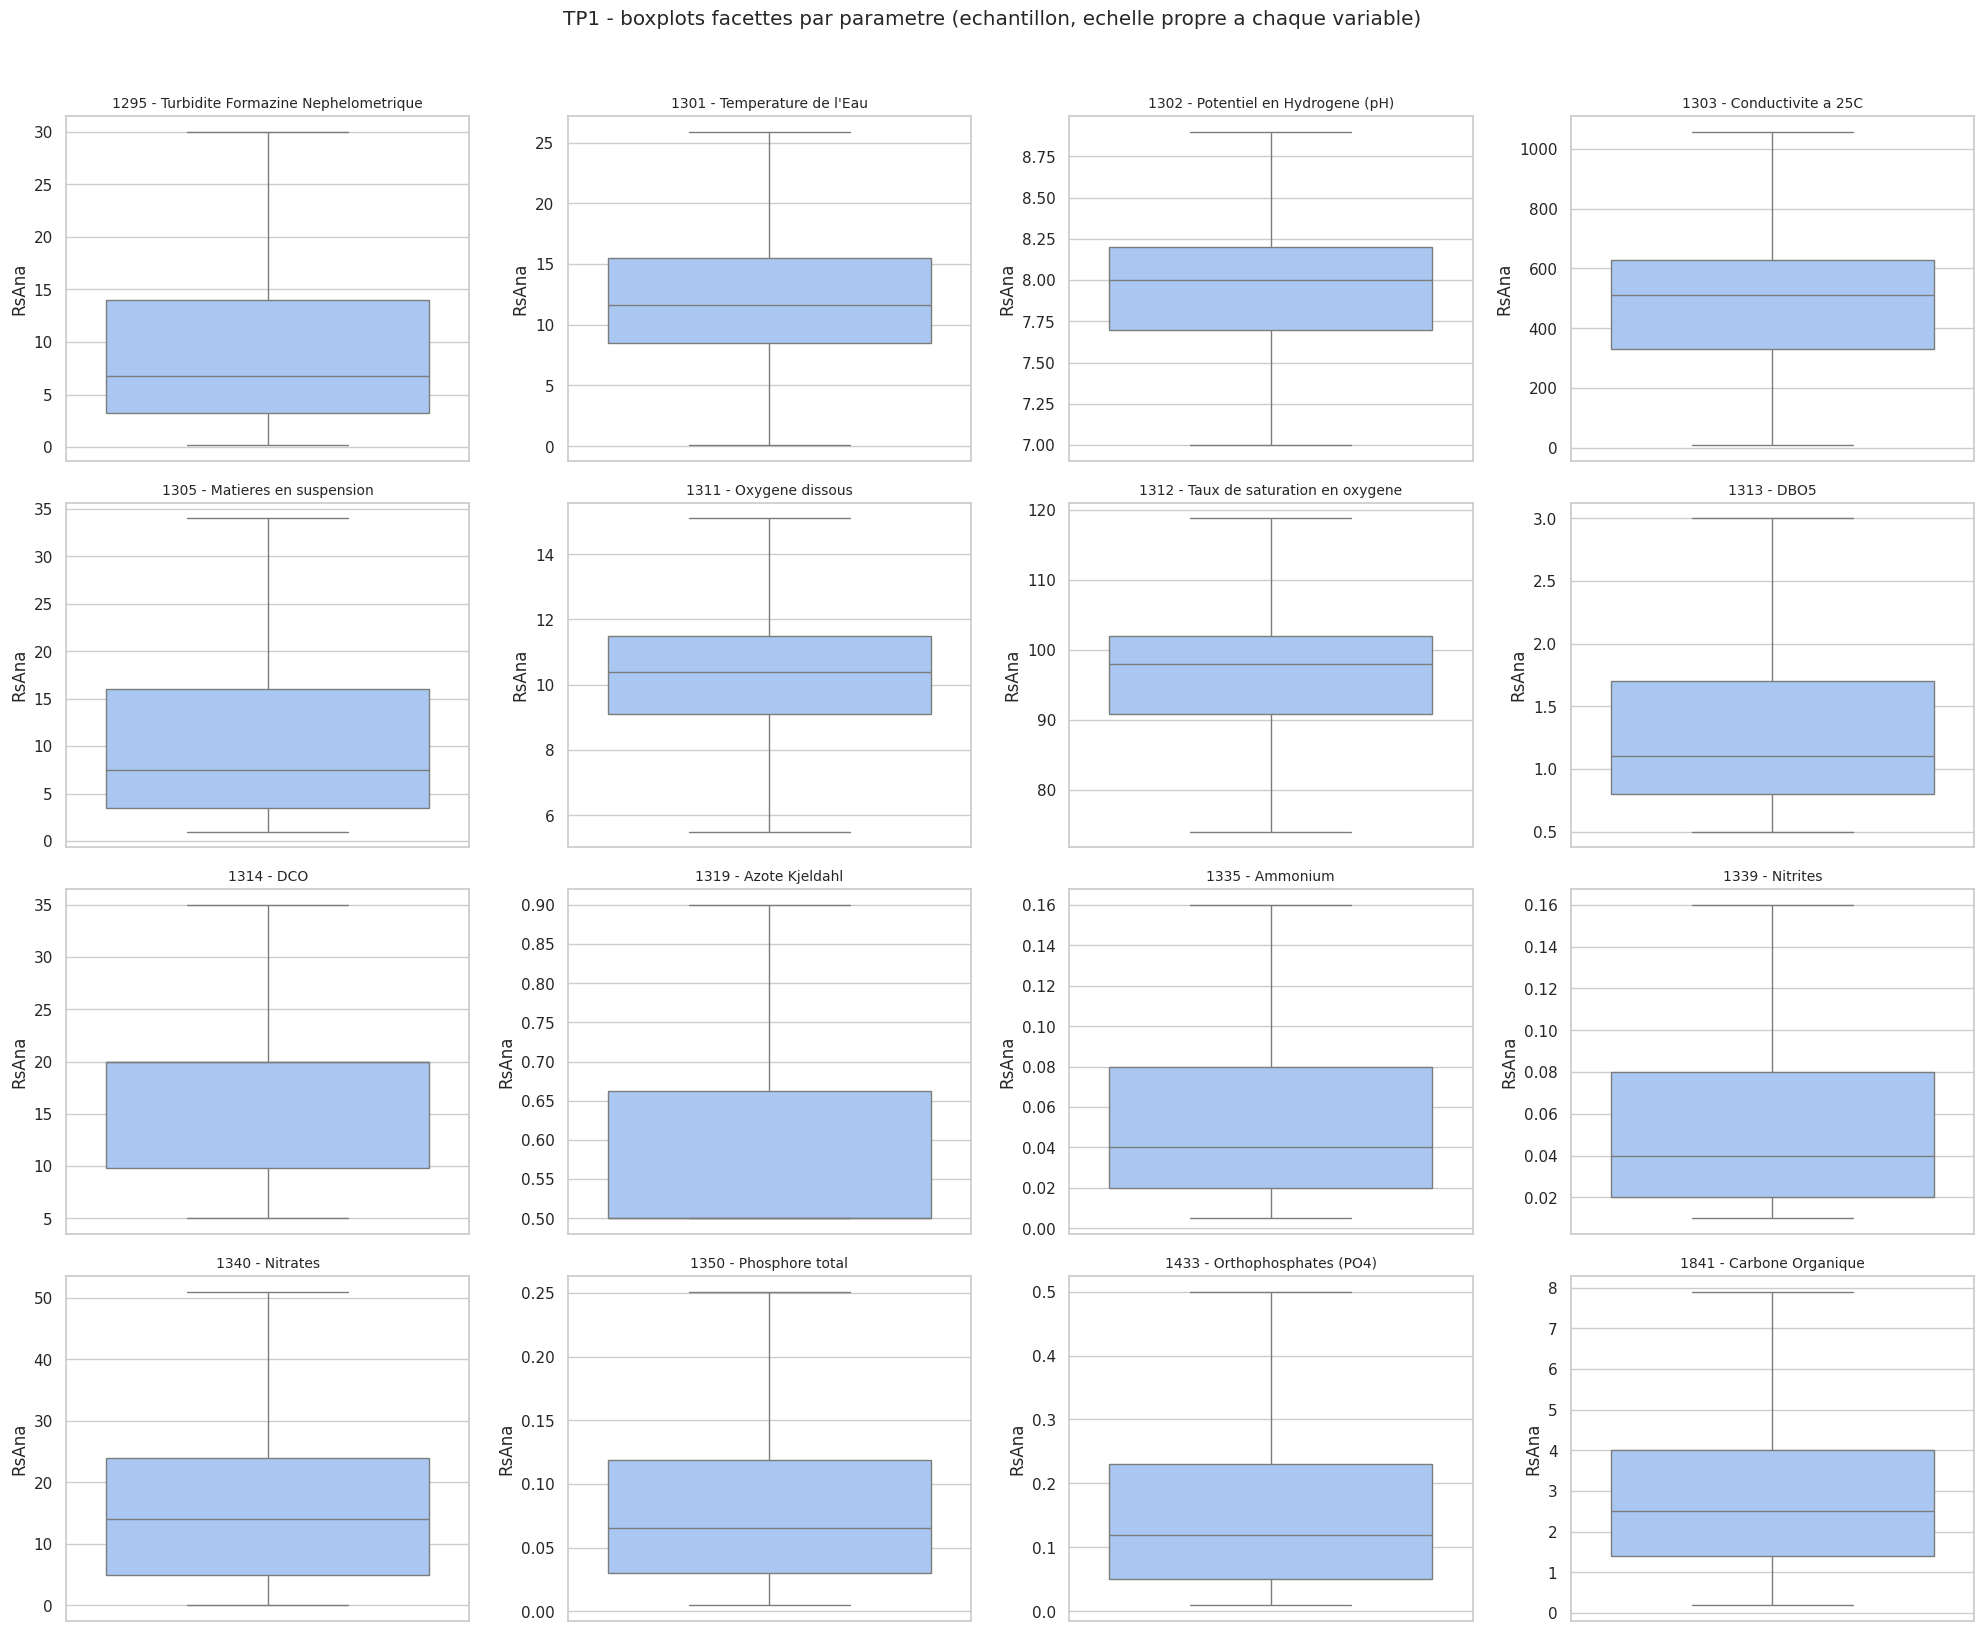

In [16]:
fig, axes = plt.subplots(4, 4, figsize=(20, 16))
for ax, code in zip(axes.flat, plot_params):
    label = f"{code} - {CORE_PARAMS[code]}"
    subset = plot_df.loc[plot_df["CdParametre"].eq(code), "RsAna"].dropna()
    if subset.empty:
        ax.set_visible(False)
        continue
    sample = subset.sample(n=min(len(subset), 1500), random_state=42)
    sns.boxplot(y=sample, ax=ax, showfliers=False, color="#9ec5fe")
    ax.set_title(label, fontsize=10)
    ax.set_xlabel("")
    ax.set_ylabel("RsAna")

for ax in axes.flat[len(plot_params):]:
    ax.set_visible(False)

plt.suptitle(
    "TP1 - boxplots facettes par parametre (echantillon, echelle propre a chaque variable)",
    y=1.02,
)
plt.tight_layout()
plt.show()


### 6.2 TP1 - Correlations entre parametres


In [17]:
station_param_median = pd.pivot_table(
    analysis_tp1,
    index="CdStationMesureEauxSurface",
    columns="CdParametre",
    values="RsAna",
    aggfunc="median",
).reindex(columns=list(CORE_PARAMS))

station_param_median.columns = [
    f"{code} - {CORE_PARAMS[code]}" for code in station_param_median.columns
]

corr = station_param_median.corr(method="spearman", min_periods=50)
corr


,1295 - Turbidite Formazine Nephelometrique,1301 - Temperature de l'Eau,1302 - Potentiel en Hydrogene (pH),1303 - Conductivite a 25C,1305 - Matieres en suspension,1311 - Oxygene dissous,1312 - Taux de saturation en oxygene,1313 - DBO5,1314 - DCO,1319 - Azote Kjeldahl,1335 - Ammonium,1339 - Nitrites,1340 - Nitrates,1350 - Phosphore total,1433 - Orthophosphates (PO4),1841 - Carbone Organique
1295 - Turbidite Formazine Nephelometrique,1.000000,-0.082013,-0.139580,0.007093,0.875384,-0.115069,-0.314540,0.497269,0.098395,0.507579,0.457711,0.439814,0.201310,0.517977,0.323922,0.511933
1301 - Temperature de l'Eau,-0.082013,1.000000,0.125732,0.227863,-0.038518,-0.498274,-0.073573,0.021118,0.069197,-0.061355,0.083497,0.134981,-0.016617,0.093360,0.129939,-0.127202
1302 - Potentiel en Hydrogene (pH),-0.139580,0.125732,1.000000,0.496028,-0.109601,0.107713,0.290282,-0.255585,-0.062325,-0.340672,-0.197537,-0.034399,0.009986,-0.155058,-0.004479,-0.438953
1303 - Conductivite a 25C,0.007093,0.227863,0.496028,1.000000,0.068951,-0.308400,-0.288569,-0.043689,-0.174388,-0.094220,0.136239,0.384425,0.356724,0.186931,0.326934,-0.237229
1305 - Matieres en suspension,0.875384,-0.038518,-0.109601,0.068951,1.000000,-0.118088,-0.274391,0.515501,0.025558,0.468590,0.467147,0.459699,0.278282,0.540489,0.376644,0.420177
1311 - Oxygene dissous,-0.115069,-0.498274,0.107713,-0.308400,-0.118088,1.000000,0.703570,-0.096067,-0.103013,-0.091305,-0.250702,-0.300186,-0.037941,-0.231722,-0.223188,-0.055423
1312 - Taux de saturation en oxygene,-0.314540,-0.073573,0.290282,-0.288569,-0.274391,0.703570,1.000000,-0.240847,0.033598,-0.280013,-0.373756,-0.440499,-0.220057,-0.372812,-0.306023,-0.313501
1313 - DBO5,0.497269,0.021118,-0.255585,-0.043689,0.515501,-0.096067,-0.240847,1.000000,0.090041,0.640751,0.618594,0.548372,0.173348,0.628161,0.458521,0.647348
1314 - DCO,0.098395,0.069197,-0.062325,-0.174388,0.025558,-0.103013,0.033598,0.090041,1.000000,0.246077,0.092125,-0.076625,-0.598340,0.034001,-0.033218,0.251074
1319 - Azote Kjeldahl,0.507579,-0.061355,-0.340672,-0.094220,0.468590,-0.091305,-0.280013,0.640751,0.246077,1.000000,0.594656,0.495403,0.109083,0.596238,0.373666,0.704365


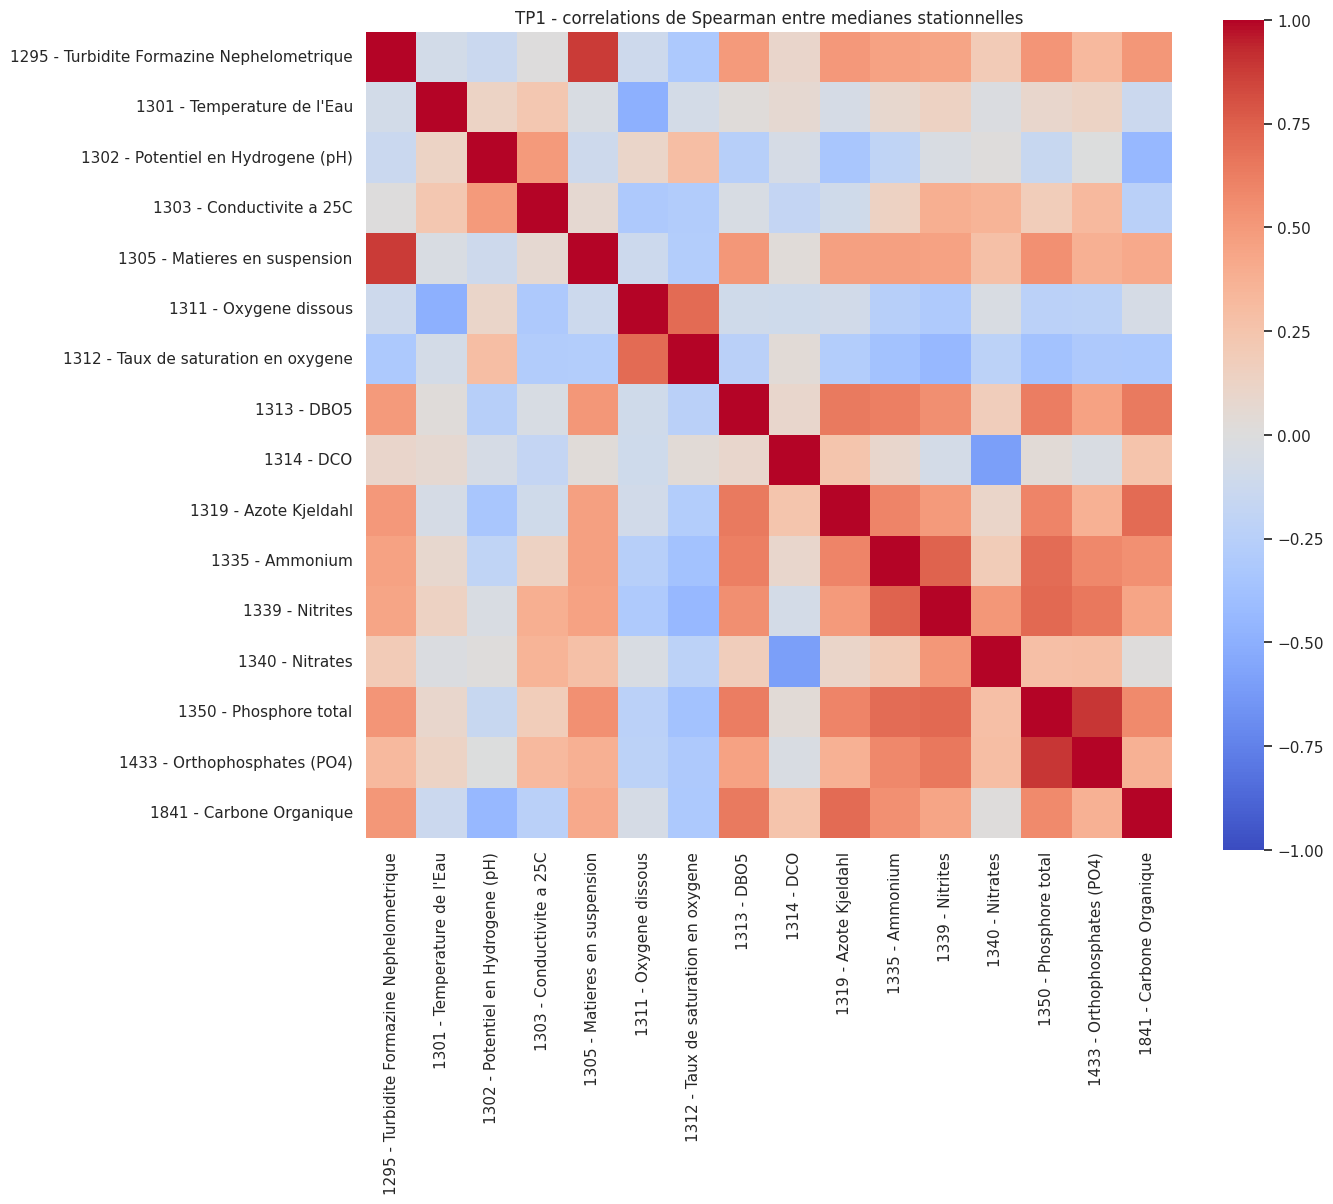

,param_1,param_2,spearman,abs_spearman
208,1350 - Phosphore total,1433 - Orthophosphates (PO4),0.894707,0.894707
3,1295 - Turbidite Formazine Nephelometrique,1305 - Matieres en suspension,0.875384,0.875384
160,1335 - Ammonium,1339 - Nitrites,0.741171,0.741171
177,1339 - Nitrites,1350 - Phosphore total,0.711390,0.711390
149,1319 - Azote Kjeldahl,1841 - Carbone Organique,0.704365,0.704365
80,1311 - Oxygene dissous,1312 - Taux de saturation en oxygene,0.703570,0.703570
162,1335 - Ammonium,1350 - Phosphore total,0.698848,0.698848
178,1339 - Nitrites,1433 - Orthophosphates (PO4),0.651191,0.651191
119,1313 - DBO5,1841 - Carbone Organique,0.647348,0.647348
113,1313 - DBO5,1319 - Azote Kjeldahl,0.640751,0.640751


In [18]:
plt.figure(figsize=(14, 12))
sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1, square=True)
plt.title("TP1 - correlations de Spearman entre medianes stationnelles")
plt.tight_layout()
plt.show()

corr_pairs = (
    corr.where(~np.eye(corr.shape[0], dtype=bool))
    .stack()
    .rename("spearman")
    .reset_index()
    .rename(columns={"level_0": "param_1", "level_1": "param_2"})
)
corr_pairs = corr_pairs.loc[corr_pairs["param_1"] < corr_pairs["param_2"]].copy()
corr_pairs["abs_spearman"] = corr_pairs["spearman"].abs()
corr_pairs.sort_values("abs_spearman", ascending=False).head(15)


## 7. TP1 - Cache local

On essaie d'ecrire en parquet si possible, sinon on bascule en pickle.


In [19]:
def write_cache(df: pd.DataFrame, stem: str) -> Path:
    parquet_path = CACHE_DIR / f"{stem}.parquet"
    pickle_path = CACHE_DIR / f"{stem}.pkl"

    try:
        df.to_parquet(parquet_path, index=False)
        print(f"Cache ecrit : {parquet_path}")
        return parquet_path
    except Exception as exc:
        df.to_pickle(pickle_path)
        print(f"Parquet indisponible ({type(exc).__name__}). Cache ecrit : {pickle_path}")
        return pickle_path


_ = write_cache(stations_scope, "stations_scope")
_ = write_cache(operations_eau, "operations_eau")
_ = write_cache(analysis_base, "analysis_base_core_params_2022")
_ = write_cache(analysis_tp1, "analysis_tp1_filtered")
_ = write_cache(station_param_median.reset_index(), "station_param_median")


Cache ecrit : /content/cache/stations_scope.parquet
Cache ecrit : /content/cache/operations_eau.parquet
Cache ecrit : /content/cache/analysis_base_core_params_2022.parquet
Cache ecrit : /content/cache/analysis_tp1_filtered.parquet
Cache ecrit : /content/cache/station_param_median.parquet


## 9. TP2 - Agregations annuelles et clustering

Le jeu fourni ne couvre qu'une annee (`2022`). Ici, l'agregation annuelle consiste donc a resumer, pour chaque station et chaque parametre, l'ensemble des mesures de 2022.

On construit deux vues :
- `mean_matrix` : moyenne annuelle ;
- `pct_matrix` : percentile oriente degradation.

Choix methodologiques retenus :
- pour `Oxygene dissous` et `Taux de saturation en oxygene`, les faibles valeurs sont defavorables, donc on prend le percentile 10 ;
- pour les autres parametres, on prend le percentile 90 ;
- pour le pH, on remplace la valeur brute par l'ecart absolu a `7.5`, puis on prend le percentile 90 de cet ecart.


In [20]:
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

TP2_LOW_BAD_PARAMS = {"1311", "1312"}
TP2_PH_REFERENCE = 7.5
TP2_PERCENTILE_HIGH = 0.90
TP2_PERCENTILE_LOW = 0.10
TP2_K_CANDIDATES = [4, 5, 6]
TP2_SELECTED_K = 4  # Choix par defaut : meilleur compromis silhouette / stabilite des classes.
TP2_COMPARISON_K = 5  # Conserve comme comparaison avec les 5 classes SEQ-Eau.

TP2_FEATURE_ORDER = [
    "1295",
    "1301",
    "1302_dev",
    "1303",
    "1305",
    "1311",
    "1312",
    "1313",
    "1314",
    "1319",
    "1335",
    "1339",
    "1340",
    "1350",
    "1433",
    "1841",
]


In [21]:
tp2_data = analysis_tp1.copy()
tp2_data["Year"] = tp2_data["DatePrel"].dt.year.astype("Int64")
tp2_data["AggDirection"] = np.where(
    tp2_data["CdParametre"].isin(TP2_LOW_BAD_PARAMS),
    "low",
    "high",
)
tp2_data["FeatureCode"] = tp2_data["CdParametre"]
tp2_data["FeatureLabel"] = tp2_data["ParamLabel"]
tp2_data["TP2Value"] = tp2_data["RsAna"]

ph_mask = tp2_data["CdParametre"].eq("1302")
tp2_data.loc[ph_mask, "FeatureCode"] = "1302_dev"
tp2_data.loc[ph_mask, "FeatureLabel"] = "1302_dev - Ecart absolu du pH a 7.5"
tp2_data.loc[ph_mask, "TP2Value"] = (
    tp2_data.loc[ph_mask, "RsAna"] - TP2_PH_REFERENCE
).abs()

tp2_feature_meta = (
    tp2_data[["FeatureCode", "FeatureLabel", "AggDirection"]]
    .drop_duplicates()
    .set_index("FeatureCode")
    .reindex(TP2_FEATURE_ORDER)
    .reset_index()
)

display(tp2_feature_meta)
tp2_data[["Year"]].drop_duplicates().sort_values("Year")


,FeatureCode,FeatureLabel,AggDirection
0,1295,1295 - Turbidite Formazine Nephelometrique,high
1,1301,1301 - Temperature de l'Eau,high
2,1302_dev,1302_dev - Ecart absolu du pH a 7.5,high
3,1303,1303 - Conductivite a 25C,high
4,1305,1305 - Matieres en suspension,high
5,1311,1311 - Oxygene dissous,low
6,1312,1312 - Taux de saturation en oxygene,low
7,1313,1313 - DBO5,high
8,1314,1314 - DCO,high
9,1319,1319 - Azote Kjeldahl,high


,Year
0,2022


In [22]:
def oriented_percentile(values: pd.Series, direction: str) -> float:
    arr = values.dropna().to_numpy()
    if len(arr) == 0:
        return np.nan
    q = TP2_PERCENTILE_LOW if direction == "low" else TP2_PERCENTILE_HIGH
    return float(np.quantile(arr, q))


records = []
group_cols = [
    "CdStationMesureEauxSurface",
    "Year",
    "FeatureCode",
    "FeatureLabel",
    "AggDirection",
]

for keys, group in tp2_data.groupby(group_cols, sort=True):
    station, year, feature_code, feature_label, direction = keys
    values = group["TP2Value"]
    records.append(
        {
            "CdStationMesureEauxSurface": station,
            "Year": year,
            "FeatureCode": feature_code,
            "FeatureLabel": feature_label,
            "AggDirection": direction,
            "n_measures": int(values.size),
            "annual_mean": float(values.mean()),
            "annual_median": float(values.median()),
            "degradation_percentile": oriented_percentile(values, direction),
        }
    )

tp2_station_year = pd.DataFrame.from_records(records)

display(tp2_station_year.head())
tp2_station_year[["Year", "FeatureCode", "n_measures"]].groupby("Year").agg(
    n_station_features=("FeatureCode", "size"),
    total_measures=("n_measures", "sum"),
)


,CdStationMesureEauxSurface,Year,FeatureCode,FeatureLabel,AggDirection,n_measures,annual_mean,annual_median,degradation_percentile
0,01000455,2022,1295,1295 - Turbidite Formazine Nephelometrique,high,1,4.32,4.32,4.32
1,01000455,2022,1301,1301 - Temperature de l'Eau,high,1,13.20,13.20,13.20
2,01000455,2022,1302_dev,1302_dev - Ecart absolu du pH a 7.5,high,1,0.40,0.40,0.40
3,01000455,2022,1303,1303 - Conductivite a 25C,high,1,584.00,584.00,584.00
4,01000455,2022,1305,1305 - Matieres en suspension,high,1,3.50,3.50,3.50


,n_station_features,total_measures
Year,,
2022,51440,331122


In [23]:
tp2_feature_labels = dict(zip(tp2_feature_meta["FeatureCode"], tp2_feature_meta["FeatureLabel"]))

mean_matrix = pd.pivot_table(
    tp2_station_year,
    index="CdStationMesureEauxSurface",
    columns="FeatureCode",
    values="annual_mean",
    aggfunc="first",
).reindex(columns=TP2_FEATURE_ORDER)

pct_matrix = pd.pivot_table(
    tp2_station_year,
    index="CdStationMesureEauxSurface",
    columns="FeatureCode",
    values="degradation_percentile",
    aggfunc="first",
).reindex(columns=TP2_FEATURE_ORDER)

mean_matrix.columns = [tp2_feature_labels[col] for col in mean_matrix.columns]
pct_matrix.columns = [tp2_feature_labels[col] for col in pct_matrix.columns]

tp2_coverage = pd.DataFrame(
    {
        "mean_missing_stations": mean_matrix.isna().sum(),
        "pct_missing_stations": pct_matrix.isna().sum(),
    }
)
tp2_coverage["mean_share_available"] = 1 - tp2_coverage["mean_missing_stations"] / len(mean_matrix)
tp2_coverage["pct_share_available"] = 1 - tp2_coverage["pct_missing_stations"] / len(pct_matrix)

print(f"Stations dans mean_matrix : {mean_matrix.shape[0]:,}")
print(f"Stations dans pct_matrix : {pct_matrix.shape[0]:,}")
display(tp2_coverage)
display(mean_matrix.head())
pct_matrix.head()


Stations dans mean_matrix : 3,321
Stations dans pct_matrix : 3,321


,mean_missing_stations,pct_missing_stations,mean_share_available,pct_share_available
1295 - Turbidite Formazine Nephelometrique,103,103,0.968985,0.968985
1301 - Temperature de l'Eau,0,0,1.000000,1.000000
1302_dev - Ecart absolu du pH a 7.5,0,0,1.000000,1.000000
1303 - Conductivite a 25C,25,25,0.992472,0.992472
1305 - Matieres en suspension,2,2,0.999398,0.999398
1311 - Oxygene dissous,0,0,1.000000,1.000000
1312 - Taux de saturation en oxygene,55,55,0.983439,0.983439
1313 - DBO5,100,100,0.969889,0.969889
1314 - DCO,1066,1066,0.679012,0.679012
1319 - Azote Kjeldahl,14,14,0.995784,0.995784


,1295 - Turbidite Formazine Nephelometrique,1301 - Temperature de l'Eau,1302_dev - Ecart absolu du pH a 7.5,1303 - Conductivite a 25C,1305 - Matieres en suspension,1311 - Oxygene dissous,1312 - Taux de saturation en oxygene,1313 - DBO5,1314 - DCO,1319 - Azote Kjeldahl,1335 - Ammonium,1339 - Nitrites,1340 - Nitrates,1350 - Phosphore total,1433 - Orthophosphates (PO4),1841 - Carbone Organique
CdStationMesureEauxSurface,,,,,,,,,,,,,,,,
01000455,4.32000,13.2000,0.4000,584.0,3.5000,9.9000,95.000,1.5000,6.200,0.5,0.02000,0.05000,22.000,0.04500,0.13000,0.73000
01000457,3.00000,16.5000,0.6000,561.0,3.7000,9.4000,96.000,1.8000,5.900,0.5,0.05000,0.20000,21.000,0.07600,0.21000,1.30000
01002236,1.50000,16.7000,0.7000,562.0,2.1000,11.1000,114.000,1.2000,7.200,0.5,0.02000,0.10000,21.000,0.06800,0.20000,1.30000
01002237,5.96375,11.8875,0.7625,569.5,13.7875,10.8875,100.500,0.9375,8.575,0.5,0.04000,0.07625,19.500,0.08875,0.23125,1.34625
01002269,5.92000,11.8750,0.7750,574.0,7.3375,10.8250,98.625,1.1250,7.650,0.5,0.04625,0.07375,19.625,0.07125,0.16250,1.44250


,1295 - Turbidite Formazine Nephelometrique,1301 - Temperature de l'Eau,1302_dev - Ecart absolu du pH a 7.5,1303 - Conductivite a 25C,1305 - Matieres en suspension,1311 - Oxygene dissous,1312 - Taux de saturation en oxygene,1313 - DBO5,1314 - DCO,1319 - Azote Kjeldahl,1335 - Ammonium,1339 - Nitrites,1340 - Nitrates,1350 - Phosphore total,1433 - Orthophosphates (PO4),1841 - Carbone Organique
CdStationMesureEauxSurface,,,,,,,,,,,,,,,,
01000455,4.320,13.20,0.40,584.0,3.5,9.90,95.0,1.50,6.2,0.5,0.020,0.050,22.0,0.0450,0.130,0.73
01000457,3.000,16.50,0.60,561.0,3.7,9.40,96.0,1.80,5.9,0.5,0.050,0.200,21.0,0.0760,0.210,1.30
01002236,1.500,16.70,0.70,562.0,2.1,11.10,114.0,1.20,7.2,0.5,0.020,0.100,21.0,0.0680,0.200,1.30
01002237,10.990,16.55,0.96,599.0,32.1,9.71,97.1,1.13,11.8,0.5,0.050,0.113,22.9,0.1372,0.383,2.09
01002269,10.559,16.49,0.96,601.5,16.8,9.77,94.7,1.43,9.9,0.5,0.072,0.110,23.6,0.0941,0.202,2.18


### 9.1 TP2 - Evaluation de plusieurs nombres de classes

On compare ici `k = 4, 5, 6` pour rester proche des 5 classes du `SEQ-Eau`, sans fixer le choix de maniere purement arbitraire.


In [24]:
def prepare_scaled_matrix(matrix: pd.DataFrame):
    imputer = SimpleImputer(strategy="median")
    scaler = StandardScaler()
    imputed = imputer.fit_transform(matrix)
    scaled = scaler.fit_transform(imputed)
    scaled_df = pd.DataFrame(scaled, index=matrix.index, columns=matrix.columns)
    return scaled_df, imputer, scaler


def evaluate_kmeans_candidates(matrix: pd.DataFrame, candidates: list[int]) -> pd.DataFrame:
    scaled_df, _, _ = prepare_scaled_matrix(matrix)
    rows = []
    for k in candidates:
        model = KMeans(n_clusters=k, n_init=50, random_state=42)
        labels = model.fit_predict(scaled_df)
        rows.append(
            {
                "n_clusters": k,
                "silhouette": silhouette_score(scaled_df, labels),
                "inertia": model.inertia_,
            }
        )
    return pd.DataFrame(rows).sort_values("n_clusters").reset_index(drop=True)


mean_k_scores = evaluate_kmeans_candidates(mean_matrix, TP2_K_CANDIDATES)
pct_k_scores = evaluate_kmeans_candidates(pct_matrix, TP2_K_CANDIDATES)

display(mean_k_scores)
pct_k_scores


,n_clusters,silhouette,inertia
0,4,0.204679,37681.338443
1,5,0.142588,35205.497838
2,6,0.144176,32608.103631


,n_clusters,silhouette,inertia
0,4,0.255992,37967.663607
1,5,0.135051,35182.380983
2,6,0.139554,32413.329732


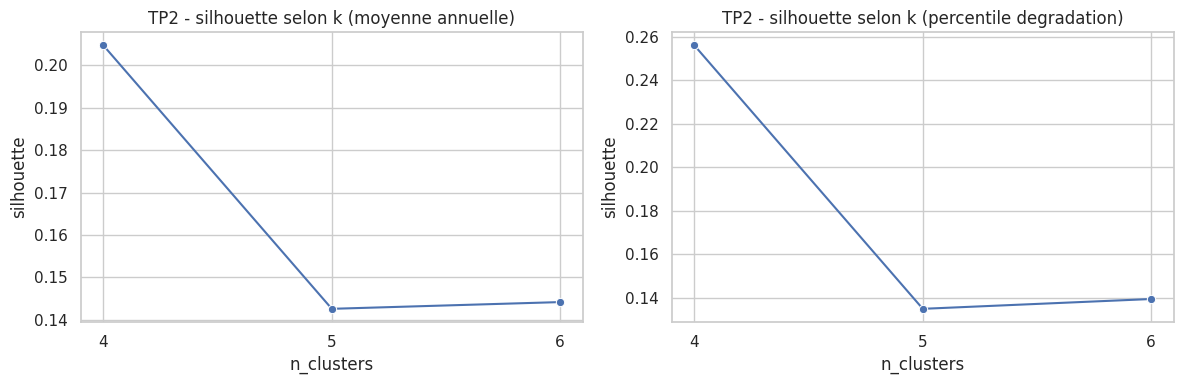

k retenu par defaut : 4 (meilleur compromis silhouette / stabilite). k de comparaison : 5 (repere SEQ-Eau). Meilleur k silhouette moyenne = 4.0, meilleur k silhouette percentile = 4.0.


In [25]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.lineplot(data=mean_k_scores, x="n_clusters", y="silhouette", marker="o", ax=axes[0])
axes[0].set_title("TP2 - silhouette selon k (moyenne annuelle)")
axes[0].set_xticks(TP2_K_CANDIDATES)

sns.lineplot(data=pct_k_scores, x="n_clusters", y="silhouette", marker="o", ax=axes[1])
axes[1].set_title("TP2 - silhouette selon k (percentile degradation)")
axes[1].set_xticks(TP2_K_CANDIDATES)

plt.tight_layout()
plt.show()

print(
    f"k retenu par defaut : {TP2_SELECTED_K} (meilleur compromis silhouette / stabilite). "
    f"k de comparaison : {TP2_COMPARISON_K} (repere SEQ-Eau). "
    f"Meilleur k silhouette moyenne = {mean_k_scores.sort_values('silhouette', ascending=False).iloc[0]['n_clusters']}, "
    f"meilleur k silhouette percentile = {pct_k_scores.sort_values('silhouette', ascending=False).iloc[0]['n_clusters']}."
)


### 9.2 TP2 - Clustering sur les deux agregations


In [26]:
def fit_tp2_clustering(matrix: pd.DataFrame, n_clusters: int, prefix: str):
    scaled_df, imputer, scaler = prepare_scaled_matrix(matrix)
    model = KMeans(n_clusters=n_clusters, n_init=50, random_state=42)
    labels = model.fit_predict(scaled_df)

    assignments = pd.DataFrame(index=matrix.index)
    assignments["cluster_id"] = labels.astype(int)
    assignments["cluster"] = assignments["cluster_id"].map(lambda i: f"{prefix}{i + 1}")
    assignments["n_missing_features"] = matrix.isna().sum(axis=1)

    raw_profiles = (
        matrix.assign(cluster=assignments["cluster"])
        .groupby("cluster")
        .median(numeric_only=True)
        .sort_index()
    )
    scaled_profiles = (
        scaled_df.assign(cluster=assignments["cluster"])
        .groupby("cluster")
        .mean(numeric_only=True)
        .sort_index()
    )
    cluster_sizes = assignments["cluster"].value_counts().sort_index().rename("n_stations")

    pca = PCA(n_components=2, random_state=42)
    coords = pca.fit_transform(scaled_df)
    pca_df = pd.DataFrame(coords, index=matrix.index, columns=["PC1", "PC2"])
    pca_df["cluster"] = assignments["cluster"]

    return {
        "assignments": assignments,
        "raw_profiles": raw_profiles,
        "scaled_profiles": scaled_profiles,
        "cluster_sizes": cluster_sizes,
        "pca_df": pca_df,
        "model": model,
        "imputer": imputer,
        "scaler": scaler,
    }


mean_cluster_result = fit_tp2_clustering(mean_matrix, TP2_SELECTED_K, prefix="M")
pct_cluster_result = fit_tp2_clustering(pct_matrix, TP2_SELECTED_K, prefix="P")

display(mean_cluster_result["cluster_sizes"])
pct_cluster_result["cluster_sizes"]


,n_stations
cluster,
M1,16
M2,2221
M3,1078
M4,6


,n_stations
cluster,
P1,823
P2,2479
P3,14
P4,5


In [32]:
if TP2_COMPARISON_K != TP2_SELECTED_K:
    mean_cluster_result_k5 = fit_tp2_clustering(mean_matrix, TP2_COMPARISON_K, prefix="M5_")
    pct_cluster_result_k5 = fit_tp2_clustering(pct_matrix, TP2_COMPARISON_K, prefix="P5_")

    comparison_k_summary = pd.DataFrame(
        [
            {
                "aggregation": "moyenne annuelle",
                "k": TP2_SELECTED_K,
                "silhouette": float(mean_k_scores.loc[mean_k_scores["n_clusters"] == TP2_SELECTED_K, "silhouette"].iloc[0]),
                "smallest_cluster": int(mean_cluster_result["cluster_sizes"].min()),
                "largest_cluster": int(mean_cluster_result["cluster_sizes"].max()),
            },
            {
                "aggregation": "moyenne annuelle",
                "k": TP2_COMPARISON_K,
                "silhouette": float(mean_k_scores.loc[mean_k_scores["n_clusters"] == TP2_COMPARISON_K, "silhouette"].iloc[0]),
                "smallest_cluster": int(mean_cluster_result_k5["cluster_sizes"].min()),
                "largest_cluster": int(mean_cluster_result_k5["cluster_sizes"].max()),
            },
            {
                "aggregation": "percentile degradation",
                "k": TP2_SELECTED_K,
                "silhouette": float(pct_k_scores.loc[pct_k_scores["n_clusters"] == TP2_SELECTED_K, "silhouette"].iloc[0]),
                "smallest_cluster": int(pct_cluster_result["cluster_sizes"].min()),
                "largest_cluster": int(pct_cluster_result["cluster_sizes"].max()),
            },
            {
                "aggregation": "percentile degradation",
                "k": TP2_COMPARISON_K,
                "silhouette": float(pct_k_scores.loc[pct_k_scores["n_clusters"] == TP2_COMPARISON_K, "silhouette"].iloc[0]),
                "smallest_cluster": int(pct_cluster_result_k5["cluster_sizes"].min()),
                "largest_cluster": int(pct_cluster_result_k5["cluster_sizes"].max()),
            },
        ]
    )

    display(comparison_k_summary)
    print("Tailles des clusters pour la comparaison k=5")
    display(mean_cluster_result_k5["cluster_sizes"])
    display(pct_cluster_result_k5["cluster_sizes"])
else:
    print("TP2_COMPARISON_K identique au k retenu ; pas de comparaison supplementaire.")


,aggregation,k,silhouette,smallest_cluster,largest_cluster
0,moyenne annuelle,4,0.204679,6,2221
1,moyenne annuelle,5,0.142588,6,1751
2,percentile degradation,4,0.255992,5,2479
3,percentile degradation,5,0.135051,5,1357


Tailles des clusters pour la comparaison k=5


,n_stations
cluster,
M5_1,1015
M5_2,6
M5_3,1751
M5_4,15
M5_5,534


,n_stations
cluster,
P5_1,14
P5_2,1357
P5_3,1280
P5_4,665
P5_5,5


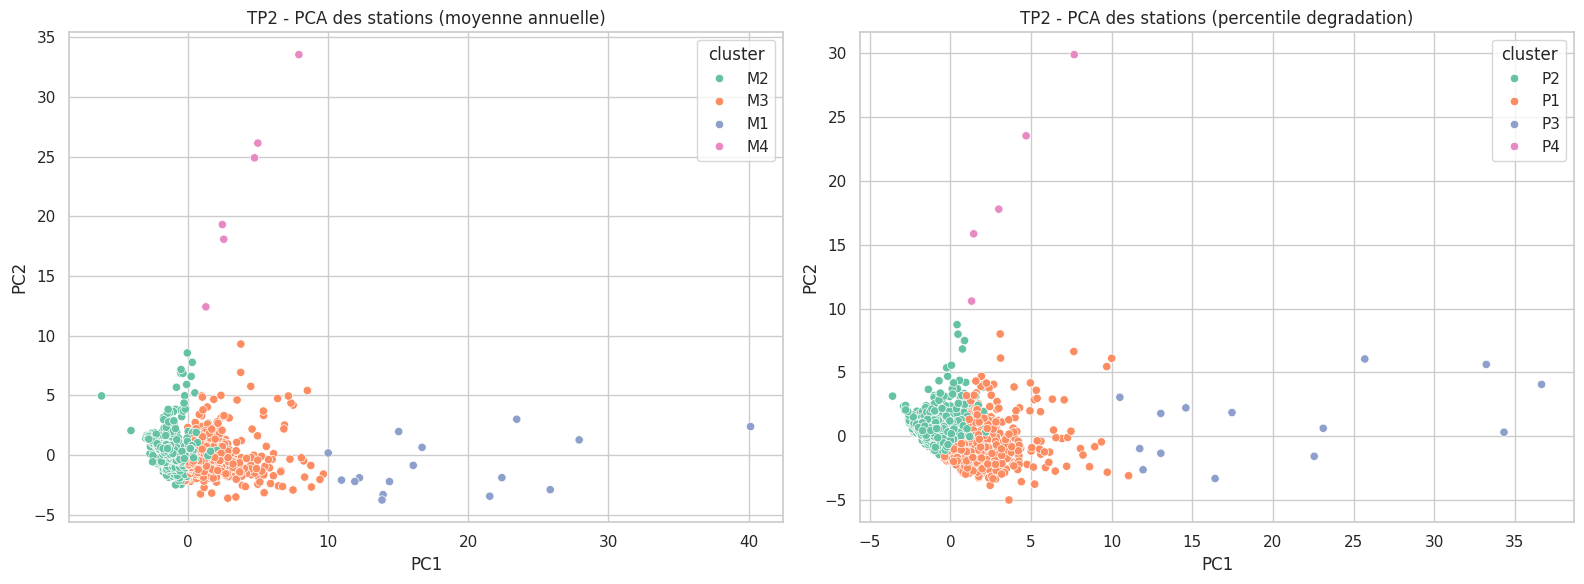

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.scatterplot(
    data=mean_cluster_result["pca_df"],
    x="PC1",
    y="PC2",
    hue="cluster",
    palette="Set2",
    ax=axes[0],
)
axes[0].set_title("TP2 - PCA des stations (moyenne annuelle)")

sns.scatterplot(
    data=pct_cluster_result["pca_df"],
    x="PC1",
    y="PC2",
    hue="cluster",
    palette="Set2",
    ax=axes[1],
)
axes[1].set_title("TP2 - PCA des stations (percentile degradation)")

plt.tight_layout()
plt.show()


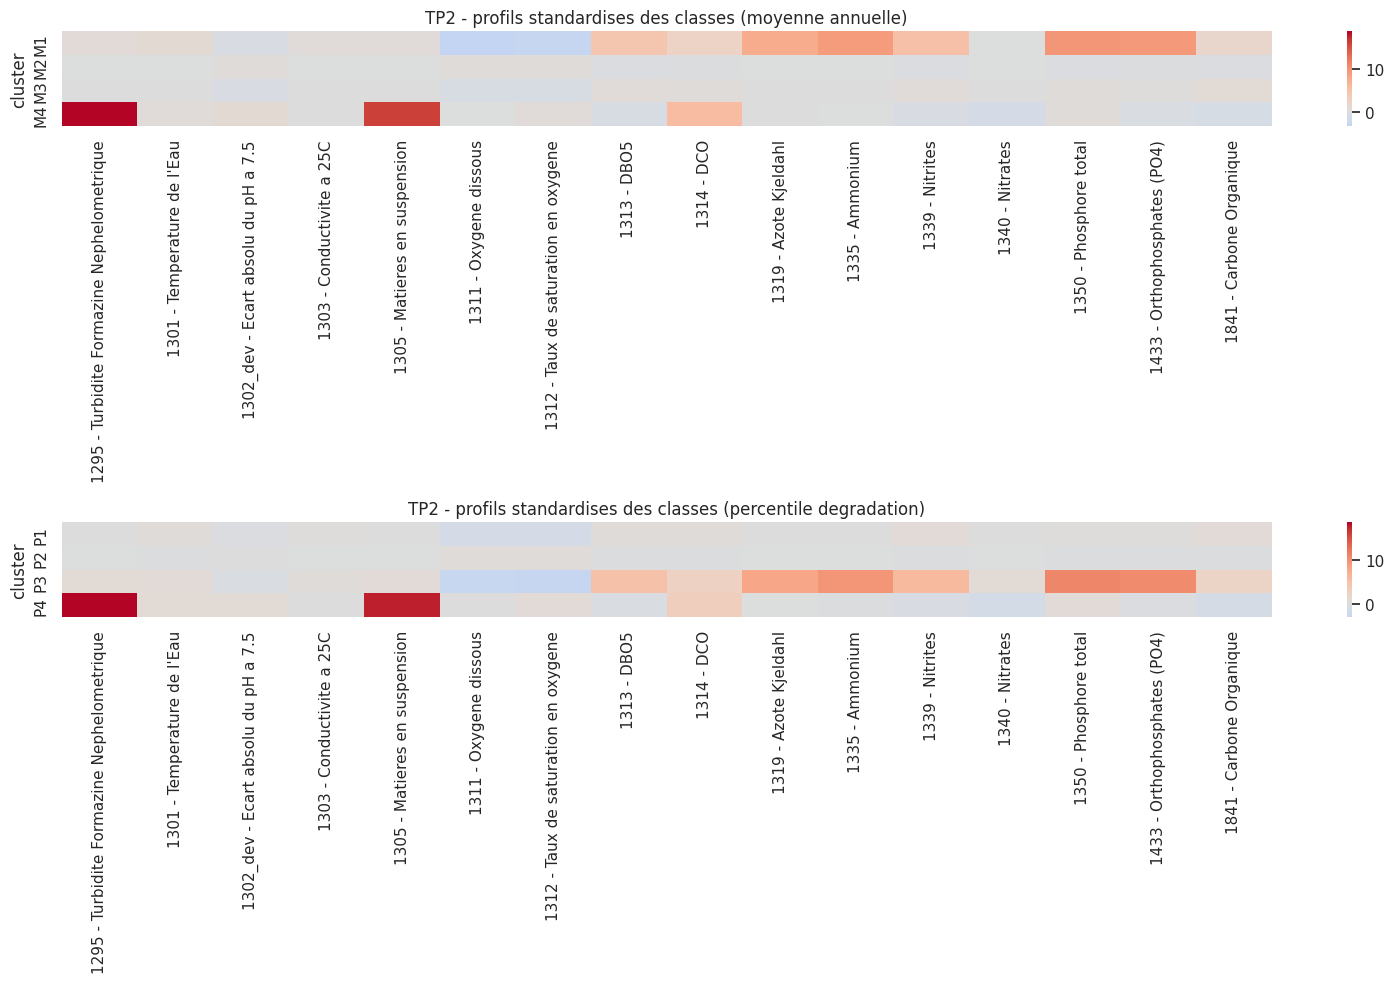

,1295 - Turbidite Formazine Nephelometrique,1301 - Temperature de l'Eau,1302_dev - Ecart absolu du pH a 7.5,1303 - Conductivite a 25C,1305 - Matieres en suspension,1311 - Oxygene dissous,1312 - Taux de saturation en oxygene,1313 - DBO5,1314 - DCO,1319 - Azote Kjeldahl,1335 - Ammonium,1339 - Nitrites,1340 - Nitrates,1350 - Phosphore total,1433 - Orthophosphates (PO4),1841 - Carbone Organique
cluster,,,,,,,,,,,,,,,,
M1,21.470833,14.360000,0.284524,992.250000,33.777451,6.383333,60.883333,3.711111,36.823529,7.521667,5.487696,0.380000,8.800417,1.440000,3.010833,7.141667
M2,7.448333,11.666667,0.557143,491.250000,8.983333,10.650000,99.066667,1.133333,15.938333,0.532500,0.033188,0.038000,15.288690,0.053500,0.096667,2.300000
M3,14.658333,11.833333,0.333333,462.500000,15.467424,9.600000,88.347222,1.800000,20.000000,0.880000,0.085000,0.095000,15.666667,0.130000,0.190000,4.970714
M4,634.181439,14.083333,0.750000,453.924242,526.208333,9.808333,100.666667,0.808333,43.481061,0.932765,0.013750,0.011667,1.561174,0.082375,0.034545,1.338750


,1295 - Turbidite Formazine Nephelometrique,1301 - Temperature de l'Eau,1302_dev - Ecart absolu du pH a 7.5,1303 - Conductivite a 25C,1305 - Matieres en suspension,1311 - Oxygene dissous,1312 - Taux de saturation en oxygene,1313 - DBO5,1314 - DCO,1319 - Azote Kjeldahl,1335 - Ammonium,1339 - Nitrites,1340 - Nitrates,1350 - Phosphore total,1433 - Orthophosphates (PO4),1841 - Carbone Organique
cluster,,,,,,,,,,,,,,,,
P1,22.00,17.430,0.57,621.5,23.00,6.95,72.00,2.255,20.9,1.10,0.135,0.1580,21.20,0.180,0.3000,5.675
P2,12.60,15.490,0.70,501.5,15.40,9.46,94.50,1.630,20.0,0.60,0.055,0.0590,20.80,0.082,0.1490,3.380
P3,46.95,18.365,0.43,1102.0,66.78,3.58,39.85,5.460,52.7,13.98,12.860,0.6175,23.30,4.320,6.8138,11.500
P4,953.10,20.800,0.89,516.8,964.00,8.40,97.50,1.100,20.0,1.10,0.020,0.0100,2.08,0.056,0.0850,0.950


In [29]:
fig, axes = plt.subplots(2, 1, figsize=(16, 10))

sns.heatmap(
    mean_cluster_result["scaled_profiles"],
    cmap="coolwarm",
    center=0,
    ax=axes[0],
)
axes[0].set_title("TP2 - profils standardises des classes (moyenne annuelle)")

sns.heatmap(
    pct_cluster_result["scaled_profiles"],
    cmap="coolwarm",
    center=0,
    ax=axes[1],
)
axes[1].set_title("TP2 - profils standardises des classes (percentile degradation)")

plt.tight_layout()
plt.show()

display(mean_cluster_result["raw_profiles"])
pct_cluster_result["raw_profiles"]


In [33]:
def _find_feature(raw_profiles: pd.DataFrame, prefix: str) -> str:
    matches = [col for col in raw_profiles.columns if col.startswith(prefix)]
    if not matches:
        raise KeyError(f"Feature introuvable pour le prefixe {prefix}")
    return matches[0]


def summarize_tp2_result(result: dict, label: str):
    raw_profiles = result["raw_profiles"]
    cluster_sizes = result["cluster_sizes"]

    turb = _find_feature(raw_profiles, "1295")
    mes = _find_feature(raw_profiles, "1305")
    oxy = _find_feature(raw_profiles, "1311")
    sat = _find_feature(raw_profiles, "1312")
    dbo5 = _find_feature(raw_profiles, "1313")
    nh4 = _find_feature(raw_profiles, "1335")
    pt = _find_feature(raw_profiles, "1350")
    po4 = _find_feature(raw_profiles, "1433")

    chemical_rank_sum = (
        raw_profiles[dbo5].rank(ascending=False)
        + raw_profiles[nh4].rank(ascending=False)
        + raw_profiles[pt].rank(ascending=False)
        + raw_profiles[po4].rank(ascending=False)
        + raw_profiles[oxy].rank(ascending=True)
        + raw_profiles[sat].rank(ascending=True)
    )

    most_chemically_degraded = chemical_rank_sum.idxmin()
    most_turbid = (raw_profiles[turb] + raw_profiles[mes]).idxmax()
    least_candidates = chemical_rank_sum.drop(index=most_turbid, errors="ignore")
    if least_candidates.empty:
        least_chemically_degraded = chemical_rank_sum.idxmax()
    else:
        least_chemically_degraded = least_candidates.idxmax()
    largest_cluster = cluster_sizes.idxmax()

    print(f"Interpretation rapide - {label}")
    print(f"- Cluster le plus representatif : {largest_cluster} ({int(cluster_sizes[largest_cluster])} stations).")
    print(f"- Cluster le plus degrade chimiquement : {most_chemically_degraded} (oxygene / saturation plus faibles et nutriments / DBO5 plus eleves).")
    print(f"- Cluster le plus charge en turbidite / MES : {most_turbid}.")
    print(f"- Cluster le moins degrade chimiquement : {least_chemically_degraded}.")


print("TP2 - interpretation automatique des clusters retenus")
summarize_tp2_result(mean_cluster_result, "moyenne annuelle")
print()
summarize_tp2_result(pct_cluster_result, "percentile degradation")


TP2 - interpretation automatique des clusters retenus
Interpretation rapide - moyenne annuelle
- Cluster le plus representatif : M2 (2221 stations).
- Cluster le plus degrade chimiquement : M1 (oxygene / saturation plus faibles et nutriments / DBO5 plus eleves).
- Cluster le plus charge en turbidite / MES : M4.
- Cluster le moins degrade chimiquement : M2.

Interpretation rapide - percentile degradation
- Cluster le plus representatif : P2 (2479 stations).
- Cluster le plus degrade chimiquement : P3 (oxygene / saturation plus faibles et nutriments / DBO5 plus eleves).
- Cluster le plus charge en turbidite / MES : P4.
- Cluster le moins degrade chimiquement : P2.


In [31]:
mean_cluster_assignments = mean_cluster_result["assignments"].reset_index()
pct_cluster_assignments = pct_cluster_result["assignments"].reset_index()

_ = write_cache(tp2_station_year, "tp2_station_year")
_ = write_cache(mean_matrix.reset_index(), "tp2_mean_matrix")
_ = write_cache(pct_matrix.reset_index(), "tp2_pct_matrix")
_ = write_cache(mean_cluster_assignments, "tp2_mean_clusters")
_ = write_cache(pct_cluster_assignments, "tp2_pct_clusters")


Cache ecrit : /content/cache/tp2_station_year.parquet
Cache ecrit : /content/cache/tp2_mean_matrix.parquet
Cache ecrit : /content/cache/tp2_pct_matrix.parquet
Cache ecrit : /content/cache/tp2_mean_clusters.parquet
Cache ecrit : /content/cache/tp2_pct_clusters.parquet


## 10. TP3 - Visualisation geographique et interpretation

Objectif de cette section :
- convertir les stations en objets geographiques ;
- cartographier les classes du TP2 ;
- regarder comment les clusters se repartissent par region ;
- prevoir un crochet propre pour ajouter ensuite Corine Land Cover et, si besoin, BD Carthage.


### 10.1 TP3 - Preparation geographique des stations

Les coordonnees des stations sont en pratique compatibles avec le systeme `Lambert-93` (`EPSG:2154`).
On construit deux couches de points : une pour le clustering sur moyenne annuelle, une pour le clustering sur percentile de degradation.


In [42]:
try:
    import geopandas as gpd
except ImportError as exc:
    raise ModuleNotFoundError(
        "Installer `geopandas` et `pyogrio` dans la cellule dependances avant d'executer le TP3."
    ) from exc

TP3_CRS_SOURCE = "EPSG:2154"  # Lambert-93
TP3_CRS_DISPLAY = "EPSG:4326"

TP3_STATION_COLUMNS = [
    "CdStationMesureEauxSurface",
    "LbStationMesureEauxSurface",
    "CoordXStationMesureEauxSurface",
    "CoordYStationMesureEauxSurface",
    "LbRegion",
    "LbDepartement",
    "NomCoursdEau",
    "NomMasseDEau",
]

station_tp3 = (
    stations_scope[TP3_STATION_COLUMNS]
    .drop_duplicates(subset="CdStationMesureEauxSurface")
    .copy()
)
station_tp3["LbRegion"] = station_tp3["LbRegion"].fillna("Region inconnue")
station_tp3["LbDepartement"] = station_tp3["LbDepartement"].fillna("Departement inconnu")


def prepare_assignment_table(result: dict) -> pd.DataFrame:
    assignments = result["assignments"].reset_index()
    if "CdStationMesureEauxSurface" not in assignments.columns:
        assignments = assignments.rename(columns={assignments.columns[0]: "CdStationMesureEauxSurface"})
    return assignments


def build_station_cluster_gdf(result: dict, label: str):
    assignments = prepare_assignment_table(result)
    frame = assignments.merge(
        station_tp3,
        on="CdStationMesureEauxSurface",
        how="left",
        validate="1:1",
    )

    n_missing_coords = frame[["CoordXStationMesureEauxSurface", "CoordYStationMesureEauxSurface"]].isna().any(axis=1).sum()
    frame = frame.dropna(subset=["CoordXStationMesureEauxSurface", "CoordYStationMesureEauxSurface"]).copy()

    gdf = gpd.GeoDataFrame(
        frame,
        geometry=gpd.points_from_xy(
            frame["CoordXStationMesureEauxSurface"],
            frame["CoordYStationMesureEauxSurface"],
        ),
        crs=TP3_CRS_SOURCE,
    )

    gdf_wgs84 = gdf.to_crs(TP3_CRS_DISPLAY)
    gdf["longitude"] = gdf_wgs84.geometry.x
    gdf["latitude"] = gdf_wgs84.geometry.y
    gdf["cluster"] = gdf["cluster"].astype("string")

    print(f"Stations cartographiables ({label}) : {len(gdf):,}")
    print(f"Stations exclues pour coordonnees manquantes ({label}) : {n_missing_coords:,}")
    print(f"Emprise {label} en Lambert-93 : {np.round(gdf.total_bounds, 0)}")
    return gdf


mean_station_gdf = build_station_cluster_gdf(mean_cluster_result, "moyenne annuelle")
pct_station_gdf = build_station_cluster_gdf(pct_cluster_result, "percentile degradation")

mean_station_gdf.head()


Stations cartographiables (moyenne annuelle) : 3,321
Stations exclues pour coordonnees manquantes (moyenne annuelle) : 0
Emprise moyenne annuelle en Lambert-93 : [ 130509. 6062386. 1241008. 7079860.]
Stations cartographiables (percentile degradation) : 3,321
Stations exclues pour coordonnees manquantes (percentile degradation) : 0
Emprise percentile degradation en Lambert-93 : [ 130509. 6062386. 1241008. 7079860.]


,CdStationMesureEauxSurface,cluster_id,cluster,n_missing_features,LbStationMesureEauxSurface,CoordXStationMesureEauxSurface,CoordYStationMesureEauxSurface,LbRegion,LbDepartement,NomCoursdEau,NomMasseDEau,geometry,longitude,latitude
0,01000455,1,M2,0,LA COURSE/CANCHE À BEUSSENT (62),616857.52,7053666.78,Hauts-de-France,Pas-de-Calais,<NA>,<NA>,POINT (616857.52 7053666.78),1.828148,50.574586
1,01000457,1,M2,0,LA COURSE/CANCHE À RECQUES SUR COURSE (62),613745.31,7048324.23,Hauts-de-France,Pas-de-Calais,<NA>,<NA>,POINT (613745.31 7048324.23),1.785447,50.526218
2,01002236,1,M2,0,LA COURSE SUR CANCHE A MONTCAVREL (62),614157.15,7046277.46,Hauts-de-France,Pas-de-Calais,<NA>,<NA>,POINT (614157.15 7046277.46),1.791687,50.507906
3,01002237,1,M2,0,HEM ET MEULESTROM A TOURNEHEM SUR LA HEM (62) [3],633578.79,7079859.79,Hauts-de-France,Pas-de-Calais,<NA>,<NA>,POINT (633578.79 7079859.79),2.059403,50.811615
4,01002269,1,M2,0,HEM ET MEULESTROM A TOURNEHEM SUR LA HEM (62) [2],633411.66,7079769.52,Hauts-de-France,Pas-de-Calais,<NA>,<NA>,POINT (633411.66 7079769.52),2.057052,50.810787


### 10.2 TP3 - Cartes des classes de stations

On commence par une carte simple des points, sans fond externe. Cette version suffit deja pour verifier si certaines classes se concentrent dans des zones particulierees.


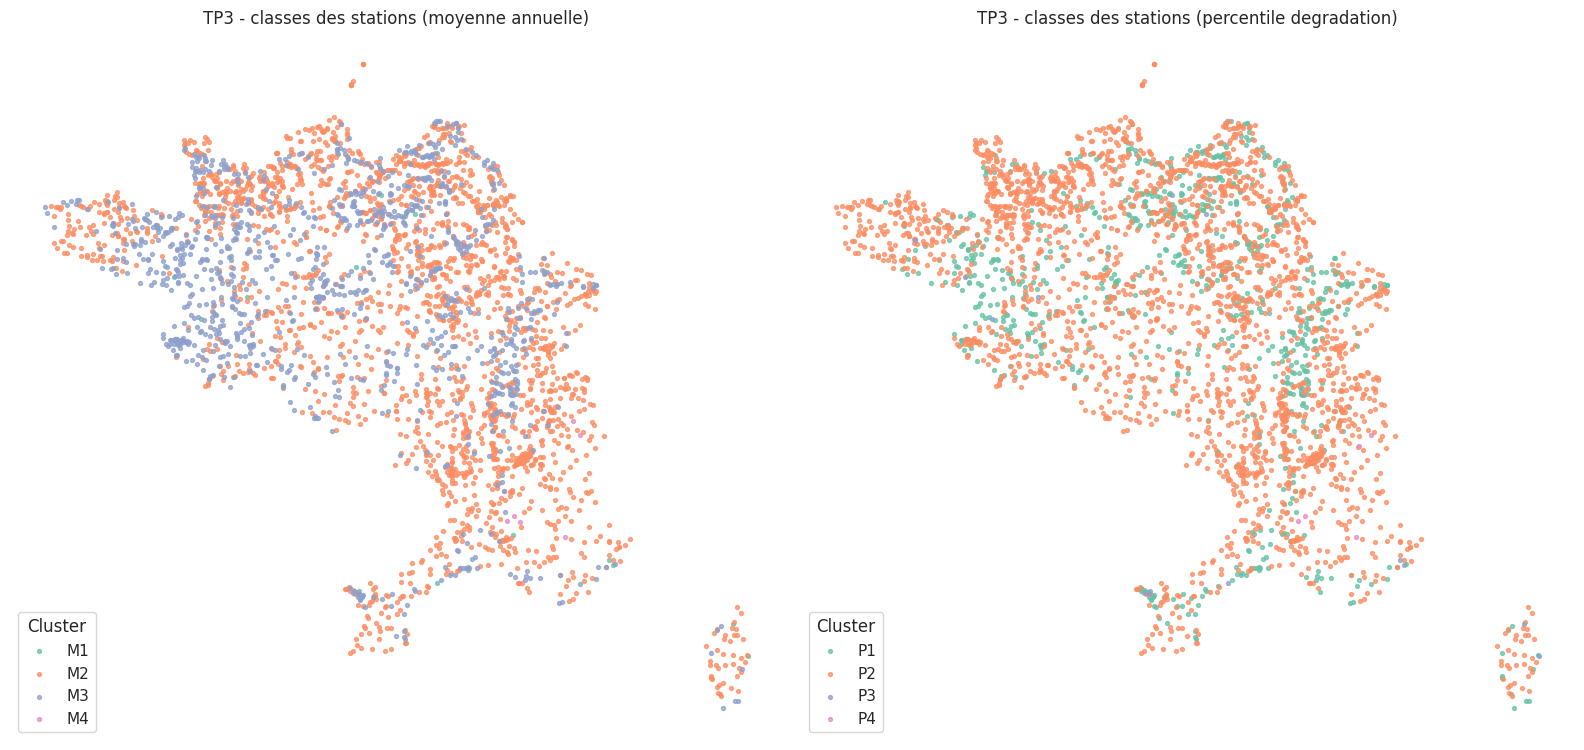

In [43]:
def plot_station_clusters(ax, gdf: "gpd.GeoDataFrame", title: str, palette_name: str = "Set2", marker_size: float = 8):
    cluster_order = sorted(gdf["cluster"].dropna().unique().tolist())
    palette = sns.color_palette(palette_name, n_colors=len(cluster_order))
    color_map = dict(zip(cluster_order, palette))

    for cluster in cluster_order:
        subset = gdf.loc[gdf["cluster"].eq(cluster)]
        subset.plot(
            ax=ax,
            markersize=marker_size,
            alpha=0.75,
            color=color_map[cluster],
            label=cluster,
        )

    ax.set_title(title)
    ax.set_axis_off()
    ax.set_aspect("equal")
    ax.legend(title="Cluster", loc="lower left", frameon=True)
    return color_map


fig, axes = plt.subplots(1, 2, figsize=(16, 10))

_ = plot_station_clusters(
    axes[0],
    mean_station_gdf,
    "TP3 - classes des stations (moyenne annuelle)",
)
_ = plot_station_clusters(
    axes[1],
    pct_station_gdf,
    "TP3 - classes des stations (percentile degradation)",
)

plt.tight_layout()
plt.show()


### 10.3 TP3 - Lecture regionale des classes

Cette etape ne remplace pas une vraie carte d'occupation du sol, mais elle aide deja a dire si certaines classes sont sur-representees dans certaines regions.


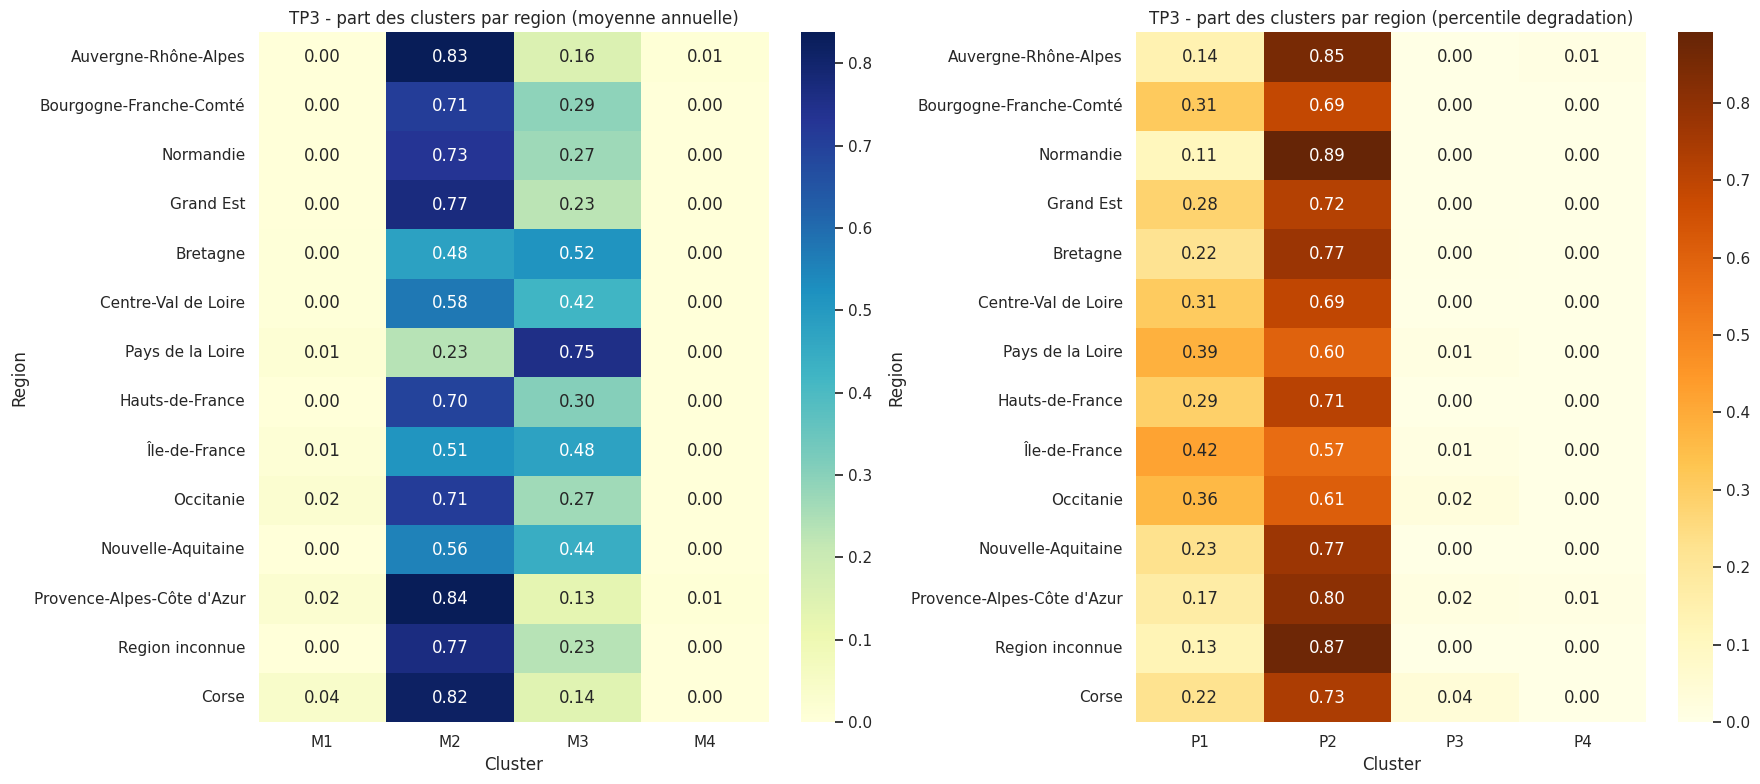

Regions les plus nettement associees a un cluster (moyenne annuelle)


,n_stations,cluster_dominant,part_cluster_dominant
LbRegion,,,
Provence-Alpes-Côte d'Azur,123,M2,0.837398
Auvergne-Rhône-Alpes,568,M2,0.834507
Corse,49,M2,0.816327
Grand Est,289,M2,0.771626
Region inconnue,86,M2,0.767442
Pays de la Loire,228,M3,0.754386
Normandie,357,M2,0.731092
Occitanie,162,M2,0.709877
Bourgogne-Franche-Comté,446,M2,0.708520


Regions les plus nettement associees a un cluster (percentile degradation)


,n_stations,cluster_dominant,part_cluster_dominant
LbRegion,,,
Normandie,357,P2,0.890756
Region inconnue,86,P2,0.872093
Auvergne-Rhône-Alpes,568,P2,0.852113
Provence-Alpes-Côte d'Azur,123,P2,0.804878
Bretagne,252,P2,0.773810
Nouvelle-Aquitaine,144,P2,0.770833
Corse,49,P2,0.734694
Grand Est,289,P2,0.719723
Hauts-de-France,207,P2,0.710145


In [44]:
def region_cluster_tables(gdf: "gpd.GeoDataFrame"):
    counts = pd.crosstab(gdf["LbRegion"], gdf["cluster"])
    counts = counts.loc[counts.sum(axis=1).sort_values(ascending=False).index]
    shares = counts.div(counts.sum(axis=1), axis=0)
    dominant = pd.DataFrame(
        {
            "n_stations": counts.sum(axis=1),
            "cluster_dominant": shares.idxmax(axis=1),
            "part_cluster_dominant": shares.max(axis=1),
        }
    ).sort_values(["part_cluster_dominant", "n_stations"], ascending=[False, False])
    return counts, shares, dominant


mean_region_counts, mean_region_shares, mean_region_summary = region_cluster_tables(mean_station_gdf)
pct_region_counts, pct_region_shares, pct_region_summary = region_cluster_tables(pct_station_gdf)

fig, axes = plt.subplots(1, 2, figsize=(18, 8))

sns.heatmap(mean_region_shares, cmap="YlGnBu", annot=True, fmt=".2f", ax=axes[0])
axes[0].set_title("TP3 - part des clusters par region (moyenne annuelle)")
axes[0].set_xlabel("Cluster")
axes[0].set_ylabel("Region")

sns.heatmap(pct_region_shares, cmap="YlOrBr", annot=True, fmt=".2f", ax=axes[1])
axes[1].set_title("TP3 - part des clusters par region (percentile degradation)")
axes[1].set_xlabel("Cluster")
axes[1].set_ylabel("Region")

plt.tight_layout()
plt.show()

print("Regions les plus nettement associees a un cluster (moyenne annuelle)")
display(mean_region_summary.head(10))
print("Regions les plus nettement associees a un cluster (percentile degradation)")
pct_region_summary.head(10)


### 10.4 TP3 - Fonds optionnels Corine et BD Carthage

Si tu recuperes ensuite des donnees externes, renseigne ci-dessous un chemin local vers Corine Land Cover niveau 2 et, si besoin, vers BD Carthage.
Sans ces fichiers, la cellule n'echoue pas : elle affiche simplement un message et garde les cartes de points produites plus haut.


CLC path resolved: /content/drive/MyDrive/CLC12_FR_RGF_SHP/CLC12_FR_RGF.shp
BD Carthage path resolved: /content/drive/MyDrive/CoursEau_FXX-shp/CoursEau_FXX.shp


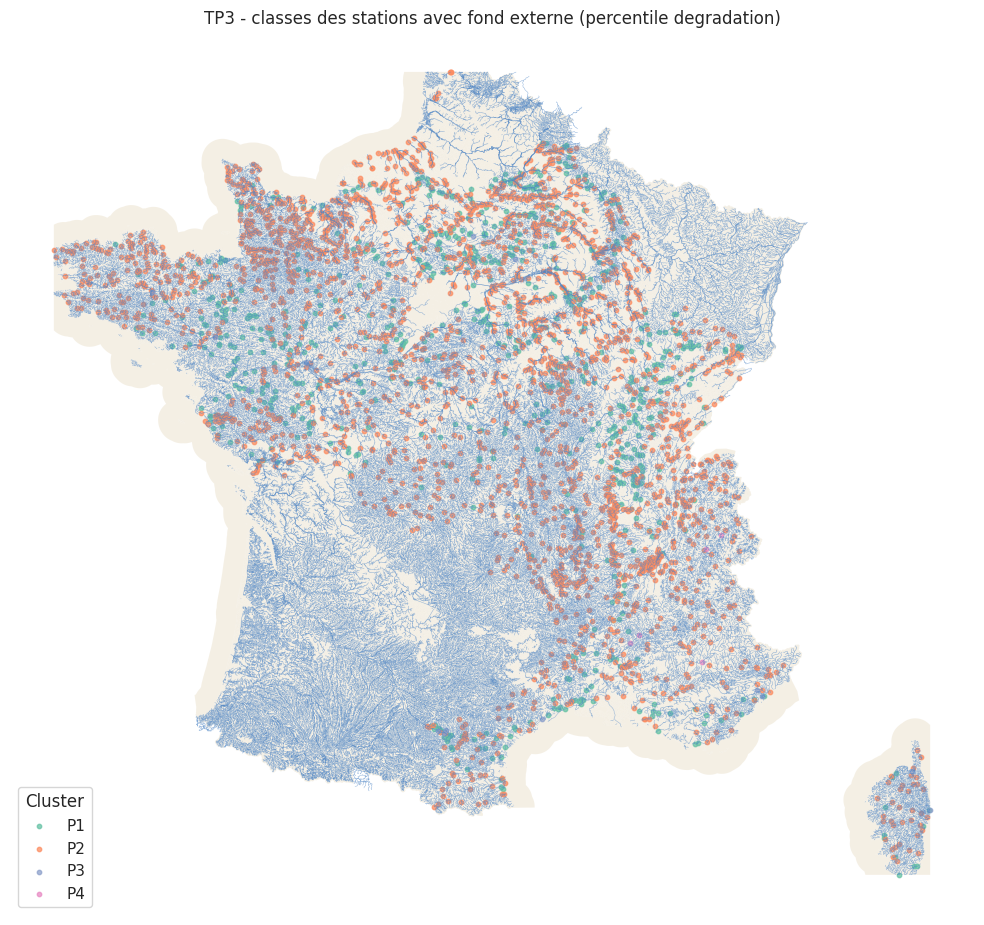

In [45]:
from shapely.geometry import box

TP3_CLC_PATH = None
TP3_CLC_LAYER = None
TP3_BD_CARTHAGE_PATH = None
TP3_BD_CARTHAGE_LAYER = None


def resolve_optional_path(explicit_path, filename, candidate_paths=None, search_roots=None):
    if explicit_path not in (None, ""):
        resolved = Path(explicit_path)
        if not resolved.exists():
            raise FileNotFoundError(f"Fichier introuvable : {resolved}")
        return resolved

    candidate_paths = candidate_paths or []
    for candidate in candidate_paths:
        candidate_path = Path(candidate)
        if candidate_path.exists():
            return candidate_path

    search_roots = search_roots or []
    for root in search_roots:
        root_path = Path(root)
        if not root_path.exists():
            continue
        matches = sorted(root_path.rglob(filename))
        if matches:
            return matches[0]

    return None


def load_optional_layer(path, layer=None, target_crs=TP3_CRS_SOURCE):
    if path in (None, ""):
        return None

    layer_path = Path(path)
    if not layer_path.exists():
        raise FileNotFoundError(f"Fichier introuvable : {layer_path}")

    read_kwargs = {"layer": layer} if layer else {}
    layer_gdf = gpd.read_file(layer_path, **read_kwargs)
    if layer_gdf.crs is None:
        raise ValueError(f"CRS manquant pour {layer_path}")
    return layer_gdf.to_crs(target_crs)


TP3_SEARCH_ROOTS = [
    Path.cwd(),
    Path("/content"),
    Path("/content/drive/MyDrive"),
]

TP3_CLC_PATH = resolve_optional_path(
    TP3_CLC_PATH,
    "CLC12_FR_RGF.shp",
    candidate_paths=[
        Path("données/CLC12_FR_RGF_SHP/CLC12_FR_RGF.shp"),
        Path("/content/données/CLC12_FR_RGF_SHP/CLC12_FR_RGF.shp"),
        Path("/content/drive/MyDrive/données/CLC12_FR_RGF_SHP/CLC12_FR_RGF.shp"),
        Path("/content/drive/MyDrive/Envir/données/CLC12_FR_RGF_SHP/CLC12_FR_RGF.shp"),
    ],
    search_roots=TP3_SEARCH_ROOTS,
)

TP3_BD_CARTHAGE_PATH = resolve_optional_path(
    TP3_BD_CARTHAGE_PATH,
    "CoursEau_FXX.shp",
    candidate_paths=[
        Path("données/CoursEau_FXX-shp/CoursEau_FXX.shp"),
        Path("/content/données/CoursEau_FXX-shp/CoursEau_FXX.shp"),
        Path("/content/drive/MyDrive/données/CoursEau_FXX-shp/CoursEau_FXX.shp"),
        Path("/content/drive/MyDrive/Envir/données/CoursEau_FXX-shp/CoursEau_FXX.shp"),
    ],
    search_roots=TP3_SEARCH_ROOTS,
)

print(f"CLC path resolved: {TP3_CLC_PATH}")
print(f"BD Carthage path resolved: {TP3_BD_CARTHAGE_PATH}")


all_bounds = np.vstack([mean_station_gdf.total_bounds, pct_station_gdf.total_bounds])
xmin, ymin = all_bounds[:, 0].min(), all_bounds[:, 1].min()
xmax, ymax = all_bounds[:, 2].max(), all_bounds[:, 3].max()
study_area = gpd.GeoDataFrame(geometry=[box(xmin, ymin, xmax, ymax)], crs=TP3_CRS_SOURCE)

clc_gdf = load_optional_layer(TP3_CLC_PATH, TP3_CLC_LAYER)
carthage_gdf = load_optional_layer(TP3_BD_CARTHAGE_PATH, TP3_BD_CARTHAGE_LAYER)

if clc_gdf is None and carthage_gdf is None:
    print(
        "Aucun fond externe configure. Pour aller jusqu'au sujet, renseigner TP3_CLC_PATH et/ou TP3_BD_CARTHAGE_PATH."
    )
else:
    fig, ax = plt.subplots(figsize=(10, 12))

    if clc_gdf is not None:
        clc_clip = gpd.clip(clc_gdf, study_area)
        clc_clip.plot(ax=ax, color="#e8ddc5", edgecolor="none", alpha=0.45)

    if carthage_gdf is not None:
        carthage_clip = gpd.clip(carthage_gdf, study_area)
        carthage_clip.plot(ax=ax, color="#4f86c6", linewidth=0.35, alpha=0.6)

    _ = plot_station_clusters(
        ax,
        pct_station_gdf,
        "TP3 - classes des stations avec fond externe (percentile degradation)",
        marker_size=10,
    )
    plt.tight_layout()
    plt.show()


### 10.5 TP3 - Reclassification CORINE en niveau 2

Le shapefile CLC12 fournit un code detaille sur 3 chiffres (`CODE_12`).
Pour coller au sujet, on recompose ici le niveau 2 de la nomenclature CORINE, plus lisible pour l'interpretation.


In [46]:
CLC_LEVEL_1_LABELS = {
    "1": "Territoires artificialises",
    "2": "Territoires agricoles",
    "3": "Forets et milieux semi-naturels",
    "4": "Zones humides",
    "5": "Surfaces en eau",
}

CLC_LEVEL_2_LABELS = {
    "11": "Zones urbanisees",
    "12": "Zones industrielles et reseaux",
    "13": "Mines, decharges et chantiers",
    "14": "Espaces verts artificialises",
    "21": "Terres arables",
    "22": "Cultures permanentes",
    "23": "Prairies",
    "24": "Zones agricoles heterogenes",
    "31": "Forets",
    "32": "Milieux arbustifs et herbaces",
    "33": "Espaces ouverts peu vegetes",
    "41": "Zones humides interieures",
    "42": "Zones humides maritimes",
    "51": "Eaux continentales",
    "52": "Eaux maritimes",
}

if clc_gdf is None:
    raise ValueError("Executer d'abord la cellule tp3optional01 avec un fichier CORINE valide.")

TP3_REFERENCE_GDF = pct_station_gdf.copy()
TP3_REFERENCE_LABEL = "percentile degradation"

clc_tp3 = clc_gdf[["CODE_12", "AREA_HA", "geometry"]].copy()
clc_tp3["CODE_12"] = clc_tp3["CODE_12"].astype("string").str.extract(r"(\d{3})", expand=False).str.zfill(3)
clc_tp3["AREA_HA"] = pd.to_numeric(clc_tp3["AREA_HA"], errors="coerce")
clc_tp3["clc_niv1_code"] = clc_tp3["CODE_12"].str[0]
clc_tp3["clc_niv2_code"] = clc_tp3["CODE_12"].str[:2]
clc_tp3["clc_niv1_label"] = clc_tp3["clc_niv1_code"].map(CLC_LEVEL_1_LABELS).fillna("Autre")
clc_tp3["clc_niv2_label"] = clc_tp3["clc_niv2_code"].map(CLC_LEVEL_2_LABELS).fillna("Autre")

clc_tp3 = gpd.clip(clc_tp3, study_area)
clc_tp3["clc_niv2_key"] = clc_tp3["clc_niv2_code"] + " - " + clc_tp3["clc_niv2_label"]

clc_niv2 = clc_tp3[["clc_niv2_key", "geometry"]].dissolve(by="clc_niv2_key", as_index=False)
clc_niv2["clc_niv2_code"] = clc_niv2["clc_niv2_key"].str[:2]
clc_niv2["clc_niv2_label"] = clc_niv2["clc_niv2_key"].str[5:]
clc_niv2["surface_km2"] = clc_niv2.geometry.area / 1_000_000
clc_niv2 = clc_niv2.sort_values("clc_niv2_code").reset_index(drop=True)

print(f"Polygones CLC clips sur la zone d'etude : {len(clc_tp3):,}")
print(f"Classes CORINE niveau 2 presentes : {clc_niv2['clc_niv2_key'].nunique():,}")
display(clc_niv2[["clc_niv2_code", "clc_niv2_label", "surface_km2"]])


Polygones CLC clips sur la zone d'etude : 273,783
Classes CORINE niveau 2 presentes : 15


,clc_niv2_code,clc_niv2_label,surface_km2
0,11,Zones urbanisees,22969.327839
1,12,Zones industrielles et reseaux,4921.555946
2,13,"Mines, decharges et chantiers",1052.773941
3,14,Espaces verts artificialises,1426.608168
4,21,Terres arables,153259.297528
5,22,Cultures permanentes,12825.686487
6,23,Prairies,85718.507537
7,24,Zones agricoles heterogenes,73701.025391
8,31,Forets,142386.768800
9,32,Milieux arbustifs et herbaces,35856.002983


### 10.6 TP3 - Carte CORINE niveau 2 et stations

Cette carte montre le contexte d'occupation du sol autour des stations. Les clusters restent deja visibles dans les cartes precedentes ; ici on se concentre sur le fond CORINE niveau 2.


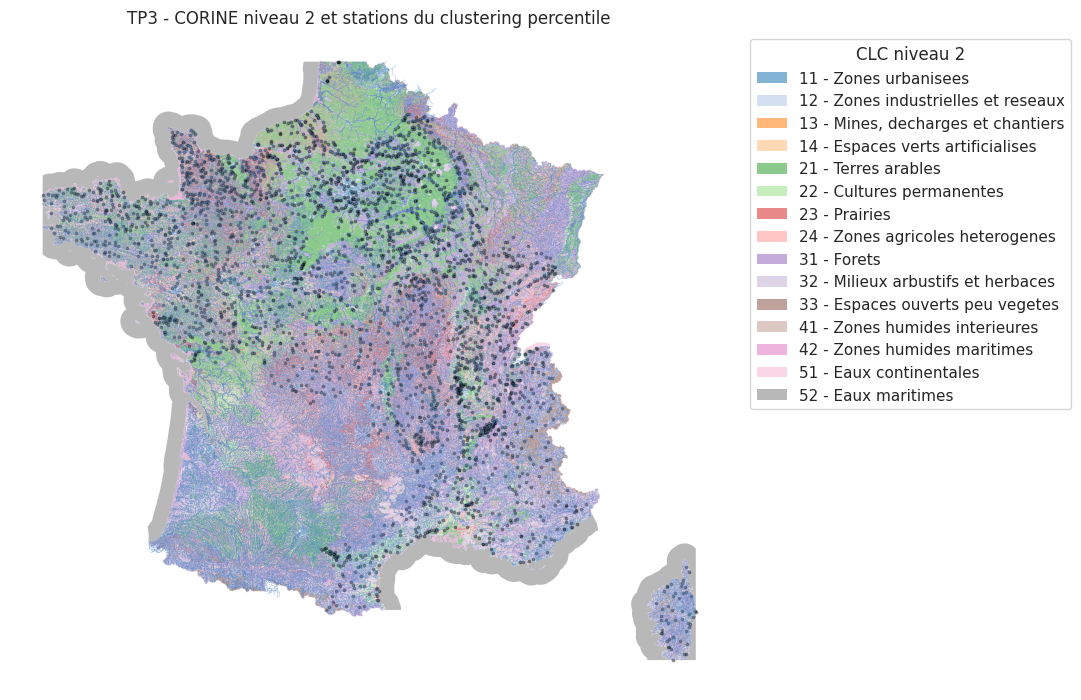

In [49]:
from matplotlib.patches import Patch

clc_palette = dict(
    zip(
        clc_niv2["clc_niv2_key"],
        sns.color_palette("tab20", n_colors=len(clc_niv2)),
    )
)
legend_handles = [
    Patch(facecolor=clc_palette[clc_key], edgecolor="none", alpha=0.55, label=clc_key)
    for clc_key in clc_niv2["clc_niv2_key"]
]

fig, ax = plt.subplots(figsize=(11, 12))

for clc_key in clc_niv2["clc_niv2_key"]:
    subset = clc_niv2.loc[clc_niv2["clc_niv2_key"].eq(clc_key)]
    subset.plot(
        ax=ax,
        color=clc_palette[clc_key],
        edgecolor="none",
        alpha=0.55,
    )

if carthage_gdf is not None:
    carthage_clip = gpd.clip(carthage_gdf, study_area)
    carthage_clip.plot(ax=ax, color="#4f86c6", linewidth=0.30, alpha=0.55)

TP3_REFERENCE_GDF.plot(ax=ax, color="black", markersize=3, alpha=0.35)
ax.set_title("TP3 - CORINE niveau 2 et stations du clustering percentile")
ax.set_axis_off()
ax.set_aspect("equal")
ax.legend(handles=legend_handles, title="CLC niveau 2", bbox_to_anchor=(1.02, 1), loc="upper left", frameon=True)
plt.tight_layout()
plt.show()


### 10.7 TP3 - Relation entre clusters et occupation du sol

On associe ici chaque station a la classe CORINE contenant son point, puis on resume la repartition des occupations du sol par cluster.
Limite importante : cette approche decrit le contexte local immediat de la station, pas l'ensemble du bassin versant.


Stations sans classe CORINE jointe : 1


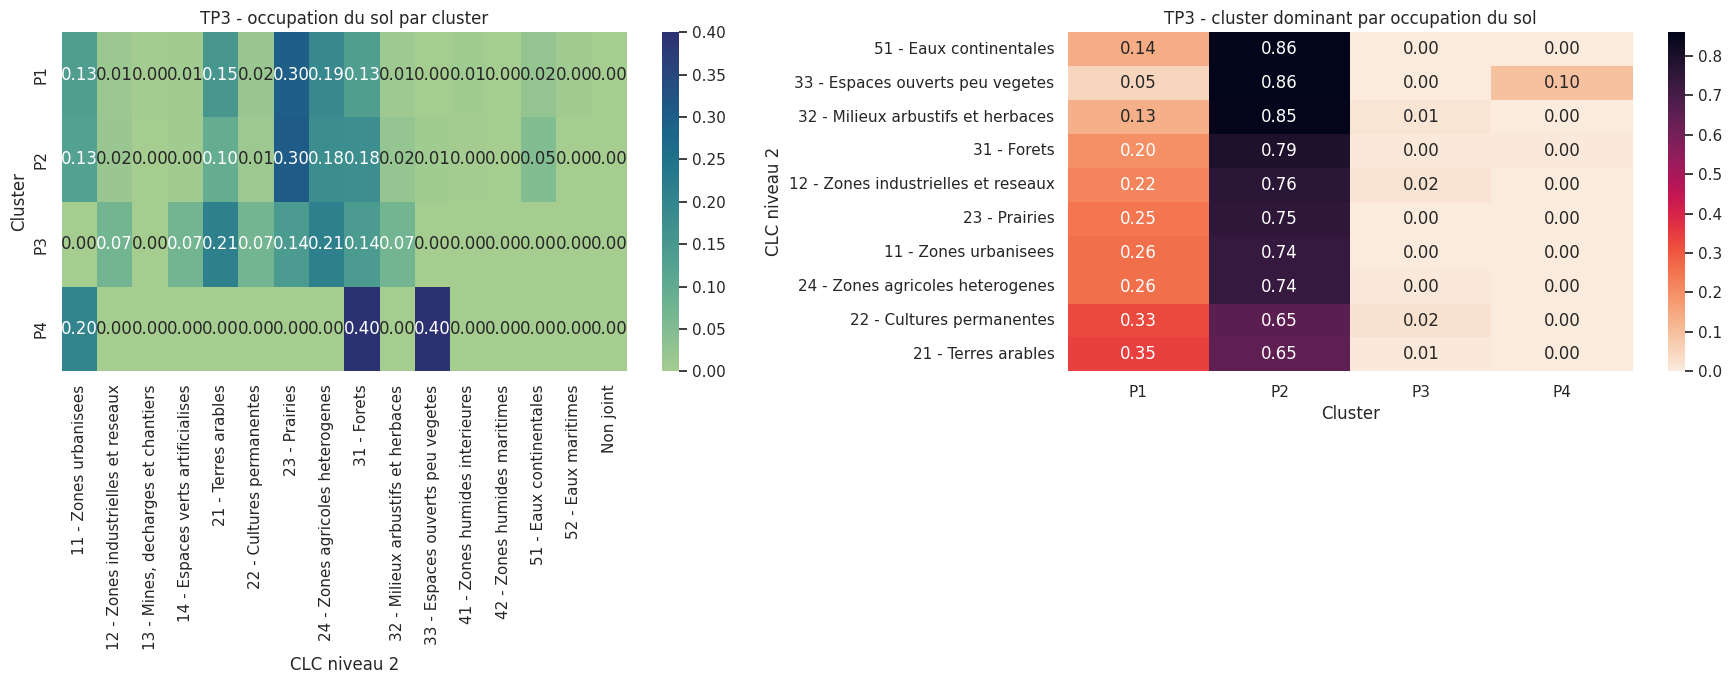

Occupation du sol dominante par cluster


,n_stations,clc_dominant,part_clc_dominant
cluster,,,
P1,823,23 - Prairies,0.298906
P2,2479,23 - Prairies,0.304962
P3,14,21 - Terres arables,0.214286
P4,5,31 - Forets,0.400000


Clusters dominants pour les occupations du sol les mieux representees


,n_stations,cluster_dominant,part_cluster_dominant
clc_niv2_key,,,
51 - Eaux continentales,142,P2,0.859155
33 - Espaces ouverts peu vegetes,21,P2,0.857143
32 - Milieux arbustifs et herbaces,68,P2,0.852941
31 - Forets,554,P2,0.794224
12 - Zones industrielles et reseaux,55,P2,0.763636
23 - Prairies,1004,P2,0.752988
11 - Zones urbanisees,426,P2,0.737089
24 - Zones agricoles heterogenes,603,P2,0.736318
22 - Cultures permanentes,43,P2,0.651163


In [48]:
tp3_station_clc = gpd.sjoin(
    TP3_REFERENCE_GDF[["CdStationMesureEauxSurface", "cluster", "LbRegion", "geometry"]].copy(),
    clc_tp3[["CODE_12", "clc_niv1_label", "clc_niv2_code", "clc_niv2_label", "clc_niv2_key", "geometry"]],
    how="left",
    predicate="intersects",
)

tp3_station_clc = (
    tp3_station_clc.sort_values(["CdStationMesureEauxSurface", "CODE_12"])
    .drop_duplicates(subset="CdStationMesureEauxSurface", keep="first")
    .drop(columns=["index_right"], errors="ignore")
)
tp3_station_clc["clc_niv2_key"] = tp3_station_clc["clc_niv2_key"].fillna("Non joint")
tp3_station_clc["clc_niv2_label"] = tp3_station_clc["clc_niv2_label"].fillna("Non joint")

n_missing_clc = tp3_station_clc["clc_niv2_key"].eq("Non joint").sum()
print(f"Stations sans classe CORINE jointe : {n_missing_clc:,}")

cluster_clc_counts = pd.crosstab(tp3_station_clc["cluster"], tp3_station_clc["clc_niv2_key"])
cluster_clc_counts = cluster_clc_counts.sort_index().sort_index(axis=1)
cluster_clc_shares = cluster_clc_counts.div(cluster_clc_counts.sum(axis=1), axis=0)

dominant_clc_by_cluster = pd.DataFrame(
    {
        "n_stations": cluster_clc_counts.sum(axis=1),
        "clc_dominant": cluster_clc_shares.idxmax(axis=1),
        "part_clc_dominant": cluster_clc_shares.max(axis=1),
    }
).sort_index()

clc_cluster_counts = pd.crosstab(tp3_station_clc["clc_niv2_key"], tp3_station_clc["cluster"])
clc_cluster_counts = clc_cluster_counts.loc[clc_cluster_counts.sum(axis=1).sort_values(ascending=False).index]
clc_cluster_shares = clc_cluster_counts.div(clc_cluster_counts.sum(axis=1), axis=0)

dominant_cluster_by_clc = pd.DataFrame(
    {
        "n_stations": clc_cluster_counts.sum(axis=1),
        "cluster_dominant": clc_cluster_shares.idxmax(axis=1),
        "part_cluster_dominant": clc_cluster_shares.max(axis=1),
    }
)
dominant_cluster_by_clc = dominant_cluster_by_clc.loc[dominant_cluster_by_clc["n_stations"].ge(20)]
dominant_cluster_by_clc = dominant_cluster_by_clc.sort_values(["part_cluster_dominant", "n_stations"], ascending=[False, False])

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
sns.heatmap(cluster_clc_shares, cmap="crest", annot=True, fmt=".2f", ax=axes[0])
axes[0].set_title("TP3 - occupation du sol par cluster")
axes[0].set_xlabel("CLC niveau 2")
axes[0].set_ylabel("Cluster")

sns.heatmap(clc_cluster_shares.loc[dominant_cluster_by_clc.index], cmap="rocket_r", annot=True, fmt=".2f", ax=axes[1])
axes[1].set_title("TP3 - cluster dominant par occupation du sol")
axes[1].set_xlabel("Cluster")
axes[1].set_ylabel("CLC niveau 2")

plt.tight_layout()
plt.show()

print("Occupation du sol dominante par cluster")
display(dominant_clc_by_cluster)
print("Clusters dominants pour les occupations du sol les mieux representees")
dominant_cluster_by_clc.head(12)


### 10.8 TP3 - Interpretation synthetique

Cette cellule formule une lecture courte des resultats `cluster x occupation du sol`.
Elle sert surtout a preparer le texte du rapport, sans remplacer l'analyse critique.


In [50]:
main_cluster = dominant_clc_by_cluster["n_stations"].idxmax()
main_cluster_landcover = dominant_clc_by_cluster.loc[main_cluster, "clc_dominant"]
main_cluster_share = dominant_clc_by_cluster.loc[main_cluster, "part_clc_dominant"]

most_specialized_cluster = dominant_clc_by_cluster["part_clc_dominant"].idxmax()
most_specialized_landcover = dominant_clc_by_cluster.loc[most_specialized_cluster, "clc_dominant"]
most_specialized_share = dominant_clc_by_cluster.loc[most_specialized_cluster, "part_clc_dominant"]

representative_clc = dominant_cluster_by_clc.head(5).copy()

print("TP3 - interpretation synthetique")
print(
    f"- Le cluster principal est {main_cluster} ; il est surtout observe dans '{main_cluster_landcover}' "
    f"({main_cluster_share:.1%} des stations du cluster)."
)
print(
    f"- Le cluster le plus specialise par occupation du sol est {most_specialized_cluster}, "
    f"associe surtout a '{most_specialized_landcover}' ({most_specialized_share:.1%})."
)
print(
    "- Globalement, l'occupation du sol au point de station discrimine peu les clusters : "
    "le cluster P2 reste dominant dans la plupart des classes CORINE bien representees."
)
print(
    "- Cette conclusion doit etre nuancee : l'analyse porte sur le polygone CORINE contenant la station, "
    "pas sur l'ensemble du bassin versant."
)
print("\nOccupations du sol les plus nettement associees a un cluster :")
display(representative_clc)


TP3 - interpretation synthetique
- Le cluster principal est P2 ; il est surtout observe dans '23 - Prairies' (30.5% des stations du cluster).
- Le cluster le plus specialise par occupation du sol est P4, associe surtout a '31 - Forets' (40.0%).
- Globalement, l'occupation du sol au point de station discrimine peu les clusters : le cluster P2 reste dominant dans la plupart des classes CORINE bien representees.
- Cette conclusion doit etre nuancee : l'analyse porte sur le polygone CORINE contenant la station, pas sur l'ensemble du bassin versant.

Occupations du sol les plus nettement associees a un cluster :


,n_stations,cluster_dominant,part_cluster_dominant
clc_niv2_key,,,
51 - Eaux continentales,142,P2,0.859155
33 - Espaces ouverts peu vegetes,21,P2,0.857143
32 - Milieux arbustifs et herbaces,68,P2,0.852941
31 - Forets,554,P2,0.794224
12 - Zones industrielles et reseaux,55,P2,0.763636
